# PARSeq (Permuted Autoregressive Sequence) cho OCR chữ laser trên PCB (PyTorch)

Notebook này thay mô hình **CRNN + CTC** bằng **PARSeq** ([baudm/parseq](https://github.com/baudm/parseq), ECCV 2022), giữ nguyên pipeline dữ liệu, tiền xử lý và bộ metric của bản CRNN để so sánh công bằng.

**Khác biệt so với CRNN + CTC**

| | CRNN + CTC | PARSeq |
|---|---|---|
| Encoder | CNN + BiLSTM | **ViT** (patch embedding, không CLS token) |
| Decoder | (không có) CTC căn chỉnh theo khung | **Transformer decoder 2 luồng** (query + content), sinh từng ký tự |
| Loss | CTC (blank) | **Cross-entropy + Permutation Language Modeling (PLM)**: huấn luyện với nhiều thứ tự ký tự (xuôi, ngược, ngẫu nhiên) |
| Suy luận | greedy CTC | **AR** (tự hồi quy) + **refine** (cloze) |
| Token đặc biệt | blank | `[E]` (kết thúc), `[B]` (bắt đầu), `[P]` (đệm) |
| Nhãn nhiều dòng | quét raster | `\n` là một ký tự bình thường |

**Hai chế độ**
- **Preset `A`, `B`**: ViT nhỏ (~5M tham số), train từ đầu.
- **Preset `P`, `Q`** (mặc định `P`): ViT-S (~23M) **nạp trọng số pretrained chính thức** của PARSeq (cần internet để tải file ~95MB; xem `CFG.pretrained`). Với ~1.7k mẫu, đây là lựa chọn nên thử trước.

> **Phiên bản v2**: đã chỉnh để tuân thủ *Cấu hình chung bắt buộc* của nhóm (xem bảng ngay bên dưới). Kiến trúc PARSeq, letterbox và autocontrast giữ nguyên.

## 0. Tuân thủ cấu hình chung bắt buộc (v2)

| Hạng mục | Cách notebook thực hiện | Nơi thực hiện |
|---|---|---|
| Dataset | Giữ **đủ 2.120 / 455 dòng**. Không loại nhãn rỗng hay ký tự lạ (chỉ báo cáo). Thiếu ảnh thì dừng với lỗi | §2 |
| Split | Một split **90/10 theo capture gốc**, seed riêng `CFG.split_seed` (không đổi theo seed huấn luyện). Xuất `split_manifest.csv` và SHA256 | §2 |
| Chống leakage | Bản `_aug` đi theo capture gốc. Train dùng gốc + `_aug`. **Val chỉ đánh giá trên mẫu gốc**. `assert` train ∩ val = ∅ | §2 |
| Test | Giữ nguyên toàn bộ `test.csv`. Chỉ chạy khi `CFG.final_test = True` | §10 |
| Nhãn | Không `upper()`, không `strip()`. Chỉ chuẩn hóa encoding (NFC) và line ending theo `norm_label` | §2 |
| Metric | Một `evaluator.py` chung: CER corpus-level (chính), WER, SeqAcc, NED. Thêm params, FPS, peak VRAM | §5, §10 |
| Checkpoint | Val CER thấp nhất. Hòa → val loss thấp hơn. Vẫn hòa → giữ epoch sớm hơn | §6 |
| Seed | Screening `[42]`, xác nhận `[42, 43, 44]` qua `CFG.seeds` | §8 |
| Precision | `auto`: BF16 nếu GPU hỗ trợ, ngược lại FP16 (T4). Ghi vào config | §1, §6 |
| Reproducibility | Mỗi run lưu `config.json`, `env.json`, split hash, Git commit, checkpoint, `val/test_predictions.csv`, `train.log`, `history.csv` | §6 |
| Board-disjoint | Chỉ bật bằng `CFG.split_mode = "board"`, xuất ra thư mục riêng, **không trộn** với bảng official | §1 |
| Kiểm tra trước GPU | Selftest 20 mẫu, phân bố độ dài nhãn / số dòng / hướng chữ / board của val | §5 |

In [1]:
import os, math, random, time, copy, string
import hashlib, json, re, sys, subprocess, platform, contextlib, unicodedata, datetime
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as T
import PIL

try:
    import cv2                  # chỉ cần nếu dùng preprocess="clahe"
except ImportError:
    cv2 = None

print("torch", torch.__version__, "| cv2:", None if cv2 is None else cv2.__version__)

torch 2.11.0+cu128 | cv2: 4.14.0


## 1. Cấu hình

- `preset`: bộ tham số mô hình. `A`/`B` train từ đầu, `P`/`Q` dùng PARSeq pretrained (ViT-S). Số token ảnh = `(img_h/patch_h) × (img_w/patch_w)`.
- `split_mode`: `"capture"` (**official**, 90/10 theo capture gốc) hoặc `"board"` (chỉ để phân tích generalization, ghi ra thư mục riêng).
- `split_seed`: seed của split, **cố định**, tách khỏi `seeds` (nếu không, đổi seed huấn luyện sẽ đổi luôn split).
- `seeds`: screening `[42]`; xác nhận phương án tốt nhất `[42, 43, 44]`.
- `precision`: `"auto"` → BF16 nếu GPU hỗ trợ ổn định (Ampere trở lên), ngược lại FP16 (T4). Có thể ép `"fp16"`, `"bf16"`, `"fp32"`.
- `max_label_len`: **hằng số chung cố định**, không suy ra từ dữ liệu. Nếu có nhãn dài hơn thì dừng với lỗi, không cắt âm thầm.
- `final_test`: để `False` cho tới khi đã khóa phương pháp trên val.

In [2]:
def locate(name, is_dir=False, roots=(".", "data", "/kaggle/input", "/content", "/content/drive")):
    for r in roots:
        if not os.path.exists(r):
            continue
        for dp, dns, fns in os.walk(r):
            if (name in dns) if is_dir else (name in fns):
                return Path(dp) / name
    return None

class CFG:
    # --- đường dẫn: mặc định tự dò, sửa tay nếu cần ---
    train_csv = Path("/kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/train.csv")
    test_csv  = Path("/kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/test.csv")
    img_root  = Path("/kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/multi_view_v2")
    out_dir   = Path("outputs_parseq")

    all_views   = ["DF_path", "PO_path", "CO_path"]
    train_views = ["DF_path"]            # thêm "PO_path", "CO_path" sau khi DF học được
    label_col   = "title"

    # --- dữ liệu chính thức (dùng để kiểm tra, không lọc) ---
    expected_train_rows = 2120           # 1.060 mẫu gốc + 1.060 bản _aug
    expected_train_orig = 1060
    expected_test_rows  = 455

    # --- nhãn: giữ nguyên hoa/thường, khoảng trắng, ký tự đặc biệt; chỉ chuẩn hóa encoding / line ending ---
    literal_backslash_n_to_newline = True   # chuỗi 2 ký tự '\n' (chữ thường) -> xuống dòng thật. Cả nhóm phải thống nhất cờ này.
    max_label_len = 64                       # hằng số CHUNG của nhóm (PARSeq cần độ dài tối đa cố định)

    # --- ảnh / mô hình (được ghi đè bởi preset) ---
    preset     = "P"
    in_ch      = 1
    img_h, img_w = 192, 192
    patch      = (12, 12)
    embed_dim, enc_depth, enc_heads = 384, 12, 6
    dec_depth, dec_heads = 1, 12
    pretrained = True                    # nạp PARSeq pretrained chính thức (chỉ cho ViT-S 384/12/6)
    perm_num   = 6
    refine_iters = 1
    dropout    = 0.1
    preprocess = "autocontrast"          # "autocontrast" | "clahe" | "none"

    # --- train ---
    batch_size    = 32
    epochs        = 100
    min_epochs    = 25                   # chưa early-stop trước mốc này
    patience      = 20
    lr            = 1e-3
    warmup_epochs = 3
    weight_decay  = 0.01
    grad_clip     = 5.0
    augment       = True                 # augmentation online, chỉ áp dụng cho train
    rot90         = True                 # Rot90 augmentation (chỉ train): mỗi lần lấy mẫu chọn ngẫu nhiên đều một góc trong rot90_angles
    rot90_angles  = (0, 90, 180, 270)    # độ, ngược chiều kim đồng hồ. Tắt: rot90 = False (hoặc (0,))
    precision     = "auto"               # "auto" | "fp16" | "bf16" | "fp32"

    # --- split ---
    split_mode  = "capture"              # "capture" = OFFICIAL | "board" = chỉ phân tích generalization
    val_ratio   = 0.10                   # official: 90/10 theo capture gốc
    board_val_ratio = 0.15               # chỉ dùng khi split_mode == "board"
    split_seed  = 42                     # seed CỦA SPLIT, không đổi
    split_manifest_in  = None            # đường dẫn split_manifest.csv dùng chung của nhóm (nếu có thì nạp, không tự chia)
    expected_split_hash = None           # dán hash của nhóm vào đây để khóa split

    # --- seed huấn luyện ---
    seeds = [42]                         # screening. Xác nhận phương án tốt nhất: [42, 43, 44]
    seed  = 42
    num_workers = 0

    # --- khác ---
    final_test = False                   # chỉ đặt True SAU KHI đã khóa phương pháp trên val
    git_commit = None                    # để None: tự dò bằng git; nếu không có git thì điền tay

_TINY = dict(embed_dim=192, enc_depth=6,  enc_heads=3, dec_depth=1, dec_heads=6,  pretrained=False, lr=5e-4)
_VITS = dict(embed_dim=384, enc_depth=12, enc_heads=6, dec_depth=1, dec_heads=12, pretrained=True,  lr=2e-4)
PRESETS = {
    "A": dict(img_h=192, img_w=192, patch=(12, 12), **_TINY),   # 256 token, từ đầu
    "B": dict(img_h=192, img_w=192, patch=(8, 8),   **_TINY),   # 576 token, từ đầu (chữ nhỏ rõ hơn)
    "P": dict(img_h=192, img_w=192, patch=(12, 12), **_VITS),   # 256 token, ViT-S pretrained
    "Q": dict(img_h=192, img_w=192, patch=(8, 8),   **_VITS),   # 576 token, ViT-S pretrained (nặng hơn)
}
def apply_preset(name):
    for k, v in PRESETS[name].items():
        setattr(CFG, k, v)
    CFG.preset = name

# tự dò đường dẫn nếu mặc định không tồn tại
if not CFG.train_csv.exists(): CFG.train_csv = locate("train.csv") or CFG.train_csv
if not CFG.test_csv.exists():  CFG.test_csv  = locate("test.csv")  or CFG.test_csv
if not CFG.img_root.exists():  CFG.img_root  = locate("multi_view_v2", is_dir=True) or CFG.img_root
print("train_csv:", CFG.train_csv, "\ntest_csv :", CFG.test_csv, "\nimg_root :", CFG.img_root)

if CFG.split_mode == "board":                      # benchmark phụ: KHÔNG trộn với kết quả official
    CFG.out_dir = Path("outputs_parseq_board_analysis")
    print("!!! split_mode = 'board': chỉ dùng phân tích generalization, ghi vào", CFG.out_dir)
apply_preset(CFG.preset)
CFG.out_dir.mkdir(parents=True, exist_ok=True)
VIEW_NAME = {"DF_path": "DF", "PO_path": "PO", "CO_path": "CO"}

def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def resolve_precision(p):
    if p != "auto":
        return p
    if not torch.cuda.is_available():
        return "fp32"
    major, _ = torch.cuda.get_device_capability()
    if major >= 8 and torch.cuda.is_bf16_supported():
        return "bf16"
    return "fp16"                                  # T4 (sm_75) và các GPU cũ hơn

set_seed(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CFG.precision_resolved = resolve_precision(CFG.precision)
AMP_DTYPE = {"fp16": torch.float16, "bf16": torch.bfloat16}.get(CFG.precision_resolved)
print("device:", device, "| precision:", CFG.precision_resolved,
      "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)

train_csv: /kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/train.csv 
test_csv : /kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/test.csv 
img_root : /kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/multi_view_v2
device: cuda | precision: fp16 | GPU: Tesla T4


## 2. Đọc dữ liệu, chuẩn hóa nhãn, chia train/val

**Không loại mẫu nào.** Nhãn rỗng, nhãn có ký tự lạ hay nhãn dài đều được giữ và chỉ **báo cáo số lượng** (nếu loại thì train/test không còn khớp bộ dữ liệu chính thức của nhóm).

**Quy tắc chuẩn hóa nhãn** (`norm_label`, chung cho cả nhóm):
1. Đọc CSV ở dạng chuỗi, `keep_default_na=False` (để nhãn như `NA` hay `NULL` không bị biến thành NaN). Ô trống → `""`.
2. Unicode NFC.
3. `\r\n` và `\r` thật → `\n`.
4. (cờ `CFG.literal_backslash_n_to_newline`) chuỗi 2 ký tự `\n` chữ thường → xuống dòng thật.
5. **Không** `strip()`, **không** `upper()`, **không** xóa ký tự.

**Split:** cột `capture_id` = tên file DF bỏ đuôi `_aug` và bỏ token view (DF/PO/CO). Chọn ngẫu nhiên 10% capture **gốc** vào val (seed `CFG.split_seed`). Mọi bản `_aug` của capture đó cũng thuộc val nhưng **không dùng để train hay đánh giá**.

In [3]:
def sha256_bytes(b): return hashlib.sha256(b).hexdigest()
def sha256_file(p):  return sha256_bytes(Path(p).read_bytes())

def read_csv_raw(path):
    # dtype=str + keep_default_na=False: không để pandas tự biến "NA"/"NULL"... thành NaN
    return pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")

train_raw = read_csv_raw(CFG.train_csv)
test_raw  = read_csv_raw(CFG.test_csv)
print("train.csv:", train_raw.shape, "| test.csv:", test_raw.shape)
if len(train_raw) != CFG.expected_train_rows or len(test_raw) != CFG.expected_test_rows:
    raise ValueError(f"Số dòng không khớp bộ chính thức: train {len(train_raw)} (cần {CFG.expected_train_rows}), "
                     f"test {len(test_raw)} (cần {CFG.expected_test_rows})")

DATA_HASHES = {"train.csv": sha256_file(CFG.train_csv), "test.csv": sha256_file(CFG.test_csv)}
print("sha256 train.csv:", DATA_HASHES["train.csv"][:16], "| test.csv:", DATA_HASHES["test.csv"][:16])

def norm_label(s):
    """Chỉ chuẩn hóa encoding + line ending. KHÔNG strip, KHÔNG đổi hoa/thường, KHÔNG xóa ký tự."""
    s = "" if s is None or (isinstance(s, float) and np.isnan(s)) else str(s)
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    if CFG.literal_backslash_n_to_newline:
        s = s.replace("\\r\\n", "\n").replace("\\n", "\n")
    return s

IMG_INDEX = {}
for dp, _, fns in os.walk(CFG.img_root):
    for fn in fns:
        IMG_INDEX.setdefault(fn, os.path.join(dp, fn))
print(f"Tìm thấy {len(IMG_INDEX)} file trong {CFG.img_root}")

def resolve_path(p):
    p = str(p).replace("\\", "/")
    for base in (CFG.img_root, Path("."), Path("data")):
        cand = Path(base) / p
        if cand.exists():
            return str(cand)
    return IMG_INDEX.get(os.path.basename(p))

LEGACY_CHARS = set("ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789 \n+-.")     # chỉ để THỐNG KÊ, không dùng để lọc

def prepare(df, name):
    df = df.copy().reset_index(drop=True)
    df.insert(0, "row_id", np.arange(len(df)))
    df["title_raw"] = df[CFG.label_col]
    df[CFG.label_col] = df["title_raw"].map(norm_label)
    for v in CFG.all_views:
        df[v + "_abs"] = df[v].map(resolve_path)
    missing = df[[v + "_abs" for v in CFG.all_views]].isna().any(axis=1)
    if missing.any():
        raise FileNotFoundError(f"[{name}] {missing.sum()} dòng thiếu ảnh, ví dụ: "
                                f"{df.loc[missing, CFG.all_views].head(3).values.tolist()}")
    L = df[CFG.label_col]
    odd = L.map(lambda s: not set(s) <= LEGACY_CHARS)
    print(f"[{name}] {len(df)} dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: {(L == '').sum()} | "
          f"có chữ thường: {L.str.contains('[a-z]').sum()} | ký tự ngoài A-Z0-9 +-.: {odd.sum()} | còn dấu '\\': {L.str.contains(chr(92), regex=False).sum()}")
    if odd.sum():
        print("   ví dụ (đã chuẩn hóa):", [repr(x) for x in L[odd].head(6)])
    return df

train_all = prepare(train_raw, "train")
test_df   = prepare(test_raw,  "test")

# ---- capture_id / is_aug / board -------------------------------------------------------------------------
AUG_RE  = re.compile(r"(^|_)aug\d*(?=_|$)", re.I)
VIEW_RE = re.compile(r"(^|_)(DF|PO|CO)(?=_|$)")

def _stem(p): return os.path.splitext(os.path.basename(str(p).replace("\\", "/")))[0]

def parse_capture(df):
    stems = df[CFG.all_views[0]].map(_stem)
    df["is_aug"] = np.logical_or.reduce([df[v].map(lambda p: bool(AUG_RE.search(_stem(p)))).values for v in CFG.all_views])
    df["capture_id"] = stems.map(lambda s: VIEW_RE.sub("", AUG_RE.sub("", s)).strip("_"))
    df["board"] = df["capture_id"].map(lambda s: s.split("_")[0])      # như get_group cũ: "100_05_..." -> "100"
    return df

train_all = parse_capture(train_all)
test_df   = parse_capture(test_df)

n_orig, n_aug = int((~train_all.is_aug).sum()), int(train_all.is_aug.sum())
print(f"[train] gốc: {n_orig} | _aug: {n_aug} | capture gốc duy nhất: {train_all.loc[~train_all.is_aug, 'capture_id'].nunique()} | "
      f"board: {train_all.board.nunique()}")
print("   ví dụ tên file -> capture_id:", [(os.path.basename(a), b, bool(c)) for a, b, c in
      train_all[[CFG.all_views[0], "capture_id", "is_aug"]].sample(4, random_state=0).values])
if n_orig != CFG.expected_train_orig or n_aug != CFG.expected_train_rows - CFG.expected_train_orig:
    print(f"[CẢNH BÁO] kỳ vọng {CFG.expected_train_orig} gốc + {CFG.expected_train_rows - CFG.expected_train_orig} _aug. "
          "Kiểm tra lại quy ước đặt tên _aug (AUG_RE) trước khi chia split.")
orig_ids = set(train_all.loc[~train_all.is_aug, "capture_id"])
orphan = train_all[train_all.is_aug & ~train_all.capture_id.isin(orig_ids)]
if len(orphan):
    print(f"[CẢNH BÁO] {len(orphan)} bản _aug không tìm thấy capture gốc, ví dụ:", orphan[CFG.all_views[0]].head(3).tolist())
if test_df.is_aug.any():
    print(f"[CẢNH BÁO] test có {int(test_df.is_aug.sum())} file _aug (test chính thức chỉ gồm mẫu gốc)")

train.csv: (2120, 4) | test.csv: (455, 4)
sha256 train.csv: 017963db097cc067 | test.csv: 20dc321533062396
Tìm thấy 7782 file trong /kaggle/input/datasets/hoangminhtit/pcb-lazertext-dataset/multi_view_v2
[train] 2120 dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: 20 | có chữ thường: 2 | ký tự ngoài A-Z0-9 +-.: 4 | còn dấu '\': 2
   ví dụ (đã chuẩn hóa): ["'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'", "'JA-80\\\\'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[test] 455 dòng (GIỮ NGUYÊN, không loại) | nhãn rỗng: 4 | có chữ thường: 3 | ký tự ngoài A-Z0-9 +-.: 3 | còn dấu '\': 1
   ví dụ (đã chuẩn hóa): ["'E8002D\\\\Ncjc1w1'", "'EM638325TS-5G\\nl403705a0t205 11M\\nETRONTECH'", "'EM638325TS-5G\\nl403705A0T205 11M\\nETRONTECH'"]
[train] gốc: 1060 | _aug: 1060 | capture gốc duy nhất: 1060 | board: 34
   ví dụ tên file -> capture_id: [('52_05_DF_7.bmp', '52_05_7', False), ('101_06_DF_3_aug.bmp', '101_06_3', True), ('54_09_DF_6.bmp', '54_09_6', False), ('102_02_DF_13.bmp',

In [4]:
# ---------------------------------------------------------------- SPLIT (một lần, cố định, có manifest + hash)
def manifest_hash(m):
    s = m[["row_id", "capture_id", "is_aug", "split"]].sort_values("row_id").to_csv(index=False, lineterminator="\n")
    return sha256_bytes(s.encode("utf-8"))

def make_split(df):
    rng = np.random.RandomState(CFG.split_seed)                    # seed của split, KHÔNG phụ thuộc seed huấn luyện
    if CFG.split_mode == "capture":
        key, ratio = "capture_id", CFG.val_ratio
        units = sorted(df.loc[~df.is_aug, key].unique())           # chỉ bốc thăm trên capture GỐC
    elif CFG.split_mode == "board":
        key, ratio = "board", CFG.board_val_ratio
        units = sorted(df[key].unique())
    else:
        raise ValueError("split_mode phải là 'capture' hoặc 'board'")
    units = np.array(units); rng.shuffle(units)
    n_val = max(1, int(round(len(units) * ratio)))
    val_units = set(units[:n_val].tolist())
    return np.where(df[key].isin(val_units), "val", "train")      # bản _aug đi theo capture/board của nó

if CFG.split_manifest_in and Path(CFG.split_manifest_in).exists():
    shared = pd.read_csv(CFG.split_manifest_in, dtype={"split": str})
    if set(shared.row_id) != set(train_all.row_id):
        raise ValueError("split_manifest_in không khớp train.csv (khác tập row_id)")
    train_all["split"] = train_all.row_id.map(shared.set_index("row_id")["split"])
    print("[split] nạp manifest dùng chung của nhóm:", CFG.split_manifest_in)
else:
    train_all["split"] = make_split(train_all)
    print(f"[split] tạo mới | mode={CFG.split_mode} | split_seed={CFG.split_seed}")
if not set(train_all.split) <= {"train", "val"}:
    raise ValueError("cột split chỉ được nhận 'train' hoặc 'val'")

manifest = train_all[["row_id", "capture_id", "board", "is_aug", "split"] + CFG.all_views].copy()
SPLIT_HASH = manifest_hash(manifest)
sfx = "" if CFG.split_mode == "capture" else "_board"
manifest.to_csv(CFG.out_dir / f"split_manifest{sfx}.csv", index=False)
(CFG.out_dir / f"split_hash{sfx}.txt").write_text(SPLIT_HASH + "\n")
if CFG.expected_split_hash and CFG.expected_split_hash != SPLIT_HASH:
    raise ValueError(f"Split hash khác của nhóm!\n  nhóm : {CFG.expected_split_hash}\n  của bạn: {SPLIT_HASH}")

tr_rows  = train_all[train_all.split == "train"]
val_rows = train_all[train_all.split == "val"]
# ---- chống leakage ----
assert not (set(tr_rows.capture_id) & set(val_rows.capture_id)), "LEAK: capture xuất hiện ở cả train và val"
assert not (set(tr_rows.row_id) & set(val_rows.row_id))
if CFG.split_mode == "board":
    assert not (set(tr_rows.board) & set(val_rows.board)), "LEAK: board xuất hiện ở cả train và val"
assert len(tr_rows) + len(val_rows) == len(train_all)

train_df = tr_rows.reset_index(drop=True)                           # gốc + _aug
val_df   = val_rows[~val_rows.is_aug].reset_index(drop=True)        # CHỈ mẫu gốc
val_aug_unused = int(val_rows.is_aug.sum())                         # _aug của capture val: không train, không đánh giá

overlap = set(test_df.capture_id) & set(train_all.capture_id)
if overlap:
    print(f"[CẢNH BÁO] {len(overlap)} capture_id của test trùng với train.csv, ví dụ: {sorted(overlap)[:3]}")

print(f"train: {len(train_df)} dòng ({int((~train_df.is_aug).sum())} gốc + {int(train_df.is_aug.sum())} _aug) | "
      f"val: {len(val_df)} mẫu gốc (+{val_aug_unused} _aug không dùng) | test: {len(test_df)}")
print(f"tỉ lệ capture gốc train/val: {(~train_df.is_aug).sum()}/{len(val_df)} = "
      f"{(~train_df.is_aug).sum() / (len(val_df) + (~train_df.is_aug).sum()):.3f}/{len(val_df) / (len(val_df) + (~train_df.is_aug).sum()):.3f}")
print("SPLIT HASH:", SPLIT_HASH)
print("-> để khóa split, đặt CFG.expected_split_hash = '%s...' (đủ 64 ký tự)" % SPLIT_HASH[:16])

[split] tạo mới | mode=capture | split_seed=42
train: 1908 dòng (954 gốc + 954 _aug) | val: 106 mẫu gốc (+106 _aug không dùng) | test: 455
tỉ lệ capture gốc train/val: 954/106 = 0.900/0.100
SPLIT HASH: 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
-> để khóa split, đặt CFG.expected_split_hash = '495f92f5e14f1048...' (đủ 64 ký tự)


In [5]:
# ---- charset: lấy từ nhãn TRAIN (đủ mọi ký tự, kể cả chữ thường, '\n', ' '); PARSeq tự thêm [E], [B], [P] ----
charset = sorted(set("".join(train_df[CFG.label_col])))
print("charset:", repr("".join(charset)), "| số ký tự:", len(charset))

# max_label_len là hằng số chung: KHÔNG cắt nhãn, KHÔNG loại mẫu -> nếu vượt thì dừng và báo
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    mx = int(d[CFG.label_col].str.len().max())
    print(f"độ dài nhãn tối đa [{name}] = {mx} (giới hạn CFG.max_label_len = {CFG.max_label_len})")
    if mx > CFG.max_label_len:
        raise ValueError(f"Nhãn {name} dài {mx} > CFG.max_label_len={CFG.max_label_len}. "
                         f"Nâng hằng số này (và dùng cùng giá trị cho cả nhóm) rồi chạy lại.")

# ký tự không có trong charset train: mô hình không thể dự đoán -> vẫn tính vào CER (không loại mẫu)
for name, d in [("val", val_df), ("test", test_df)]:
    unseen = set("".join(d[CFG.label_col])) - set(charset)
    if unseen:
        n_aff = int(d[CFG.label_col].map(lambda s: bool(set(s) & unseen)).sum())
        print(f"[cảnh báo] {name}: ký tự không có trong charset train {sorted(unseen)} ({n_aff} nhãn bị ảnh hưởng, vẫn được tính vào metric)")

lens = train_df[CFG.label_col].str.len()
print("độ dài nhãn (train): min/mean/max =", lens.min(), round(lens.mean(), 2), lens.max())
print("số dòng trung bình:", round(train_df[CFG.label_col].str.count("\n").add(1).mean(), 2),
      "| tỉ lệ nhãn nhiều dòng:", round(train_df[CFG.label_col].str.contains("\n").mean(), 3))

charset: '\n +-.0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ\\l' | số ký tự: 43
độ dài nhãn tối đa [train] = 45 (giới hạn CFG.max_label_len = 64)
độ dài nhãn tối đa [val] = 44 (giới hạn CFG.max_label_len = 64)
độ dài nhãn tối đa [test] = 47 (giới hạn CFG.max_label_len = 64)
[cảnh báo] test: ký tự không có trong charset train ['a', 'c', 'j', 't', 'w'] (2 nhãn bị ảnh hưởng, vẫn được tính vào metric)
độ dài nhãn (train): min/mean/max = 0 9.22 45
số dòng trung bình: 1.73 | tỉ lệ nhãn nhiều dòng: 0.466


## 3. Dataset, tiền xử lý ảnh và DataLoader

Tiền xử lý: tăng tương phản trên ảnh gốc → resize **giữ tỉ lệ** → đệm bằng **màu trung bình của ảnh** (thay vì trắng) → cache RAM. Augmentation nhẹ chỉ dùng cho train.

**Rot90 augmentation** (`CFG.rot90`, `CFG.rot90_angles`): chỉ trong train, mỗi lần lấy mẫu ảnh được xoay ngẫu nhiên đều theo 0°/90°/180°/270° (trên canvas vuông đã letterbox nên không đổi kích thước), sau đó mới tới augmentation nhẹ (affine, brightness/contrast). Nhãn không đổi. Val/test **không** bị xoay. Cấu hình được lưu trong `config.json` của từng run. Để làm ablation, đặt `CFG.rot90 = False`.

In [6]:
_IMG_CACHE = {}

def enhance(img):
    if CFG.preprocess == "none":
        return img
    if CFG.preprocess == "clahe" and cv2 is not None:
        arr = np.array(img)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4))
        if arr.ndim == 2:
            arr = clahe.apply(arr)
        else:
            arr = np.stack([clahe.apply(arr[..., i]) for i in range(arr.shape[2])], axis=-1)
        return Image.fromarray(arr)
    return ImageOps.autocontrast(img, cutoff=1)

def letterbox(img, W, H):
    w, h = img.size
    s = min(W / w, H / h)
    nw, nh = max(1, int(round(w * s))), max(1, int(round(h * s)))
    fill = np.array(img).reshape(-1, 1 if img.mode == "L" else 3).mean(0)
    fill = int(fill[0]) if img.mode == "L" else tuple(int(x) for x in fill)
    img = img.resize((nw, nh), Image.BICUBIC)
    canvas = Image.new(img.mode, (W, H), fill)
    canvas.paste(img, ((W - nw) // 2, (H - nh) // 2))
    return canvas

def load_image(path):
    key = (path, CFG.img_h, CFG.img_w, CFG.in_ch, CFG.preprocess)
    if key not in _IMG_CACHE:
        img = Image.open(path).convert("L" if CFG.in_ch == 1 else "RGB")
        _IMG_CACHE[key] = letterbox(enhance(img), CFG.img_w, CFG.img_h)
    return _IMG_CACHE[key]

aug_tf = T.Compose([
    T.RandomApply([T.RandomAffine(degrees=3, translate=(0.03, 0.03), scale=(0.95, 1.05), fill=128)], p=0.7),
    T.ColorJitter(brightness=0.3, contrast=0.3),
])

_TR = getattr(Image, "Transpose", Image)
_ROT_OPS = {0: None, 90: _TR.ROTATE_90, 180: _TR.ROTATE_180, 270: _TR.ROTATE_270}   # PIL: xoay ngược chiều kim đồng hồ

def random_rot90(img):
    """Rot90 augmentation: chọn ngẫu nhiên đều một góc trong CFG.rot90_angles. Nhãn giữ nguyên."""
    ang = random.choice(CFG.rot90_angles)
    op = _ROT_OPS[ang]                                    # KeyError nếu góc không phải bội số của 90
    if op is None:
        return img
    img = img.transpose(op)
    if img.size != (CFG.img_w, CFG.img_h):                # chỉ xảy ra khi kích thước vào mô hình không vuông
        img = letterbox(img, CFG.img_w, CFG.img_h)
    return img

def to_tensor(img):
    return T.Normalize([0.5] * CFG.in_ch, [0.5] * CFG.in_ch)(T.ToTensor()(img))

class ViewDataset(Dataset):
    def __init__(self, df, view, train=False, augment=None):
        self.paths  = df[view + "_abs"].tolist()
        self.titles = df[CFG.label_col].tolist()
        self.train  = train and (CFG.augment if augment is None else augment)
        for p in self.paths:        # preload + cache
            load_image(p)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = load_image(self.paths[i])
        if self.train:
            if CFG.rot90:
                img = random_rot90(img)          # chỉ train; val/test không bao giờ bị xoay
            img = aug_tf(img)
        return to_tensor(img), self.titles[i], i       # nhãn là chuỗi thô, Tokenizer nằm trong model

def collate(batch):
    xs, labels, idxs = zip(*batch)
    return torch.stack(xs), list(labels), torch.tensor(idxs)

def make_loader(df, view, train, batch_size=None, augment=None):
    bs = batch_size or (CFG.batch_size if train else 64)
    g = torch.Generator().manual_seed(CFG.seed) if train else None      # thứ tự shuffle tái lập theo seed
    return DataLoader(ViewDataset(df, view, train, augment), batch_size=bs, shuffle=train, generator=g,
                      collate_fn=collate, num_workers=CFG.num_workers)

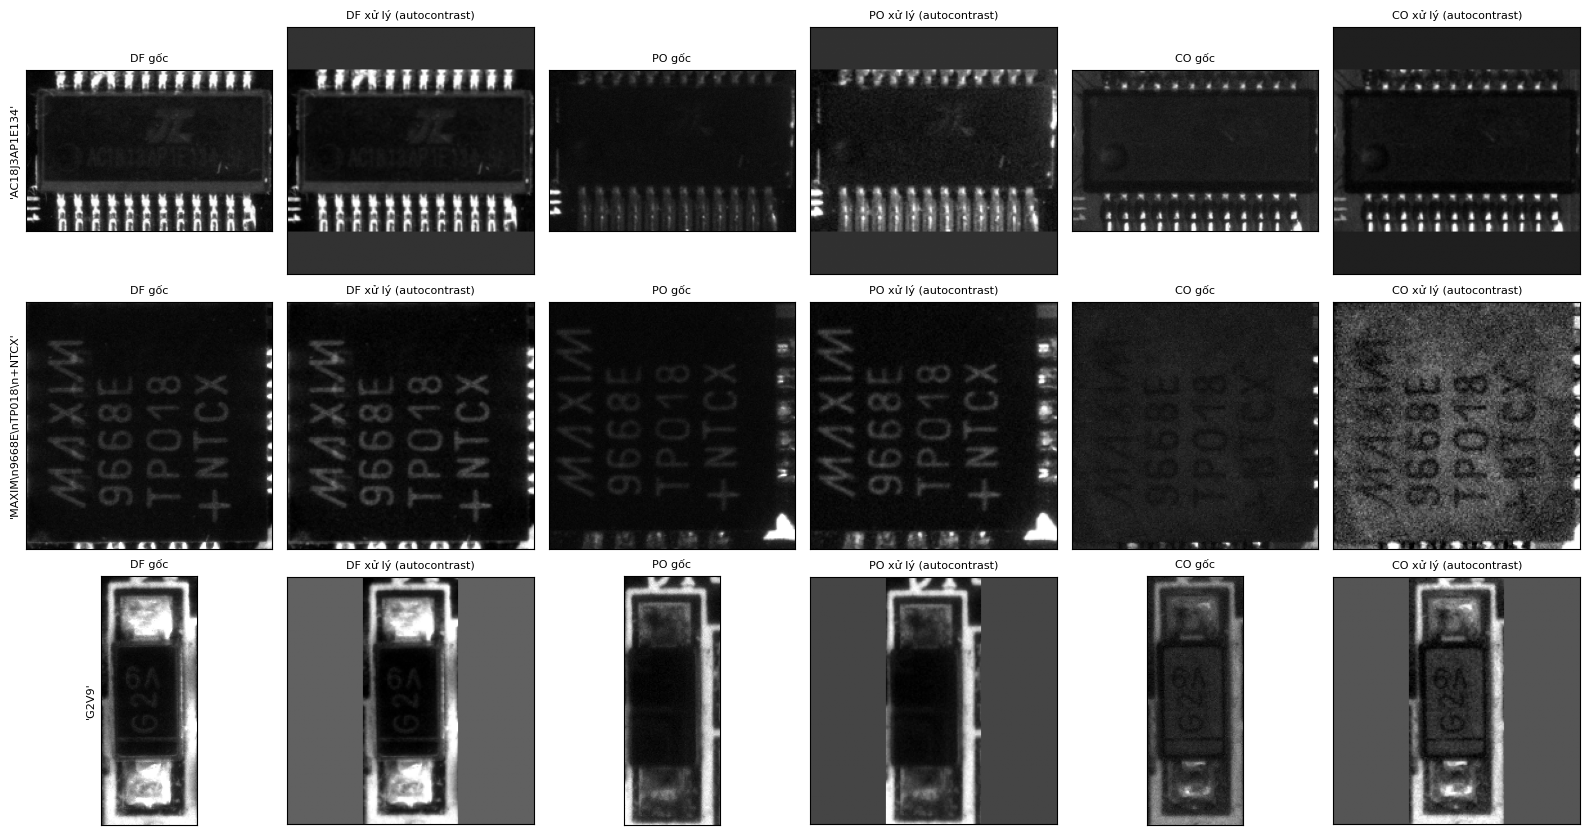

In [7]:
# ảnh gốc vs ảnh sau tiền xử lý (3 mẫu, mỗi view một cặp)
def show_preprocess(n=3):
    idx = np.random.RandomState(0).choice(len(train_df), n, replace=False)
    fig, axes = plt.subplots(n, 6, figsize=(16, 2.8 * n))
    for r, i in enumerate(idx):
        for c, v in enumerate(CFG.all_views):
            raw = Image.open(train_df[v + "_abs"][i]).convert("L")
            axes[r, 2 * c].imshow(raw, cmap="gray");                                  axes[r, 2 * c].set_title(f"{VIEW_NAME[v]} gốc", fontsize=8)
            axes[r, 2 * c + 1].imshow(load_image(train_df[v + "_abs"][i]), cmap="gray"); axes[r, 2 * c + 1].set_title(f"{VIEW_NAME[v]} xử lý ({CFG.preprocess})", fontsize=8)
        axes[r, 0].set_ylabel(repr(train_df[CFG.label_col][i]), fontsize=8)
        for a in axes[r]: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

show_preprocess()

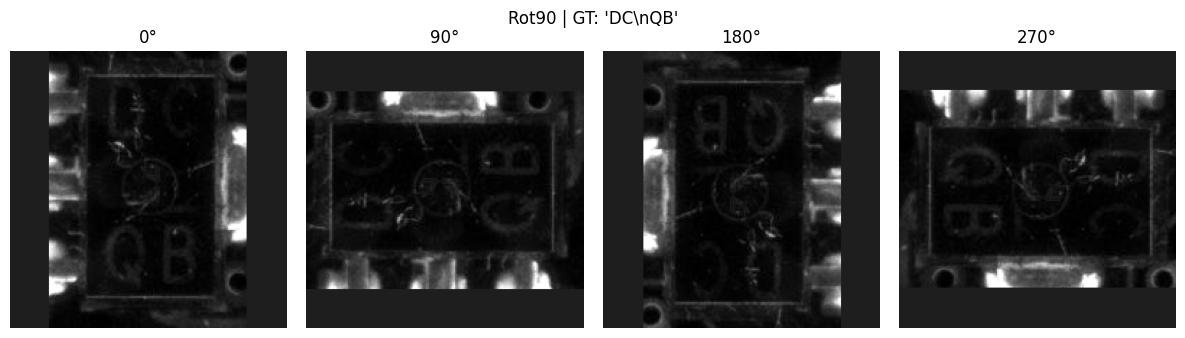

In [8]:
# xem thử Rot90: 1 mẫu train x 4 góc (chỉ để kiểm tra bằng mắt, không ảnh hưởng huấn luyện)
def show_rot90(view="DF_path", i=0):
    img = load_image(train_df[view + "_abs"][i])
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
    for ax, ang in zip(axes, (0, 90, 180, 270)):
        op = _ROT_OPS[ang]
        ax.imshow(img if op is None else img.transpose(op), cmap="gray" if CFG.in_ch == 1 else None)
        ax.set_title(f"{ang}°"); ax.axis("off")
    plt.suptitle(f"Rot90 | GT: {train_df[CFG.label_col][i]!r}"); plt.tight_layout(); plt.show()

show_rot90()


## 4. Mô hình PARSeq

```
ảnh (B, C, H, W) → ViT encoder (patch embed + pos_embed + N block) → memory (B, n_token, D)
nhãn  [B] c1 c2 ... cn [E] → Transformer decoder 2 luồng (cross-attn tới memory) → Linear → logits (B, L, n_class)
```

- **Encoder**: ViT, không CLS token; tên tham số khớp `timm`/bản gốc nên nạp được checkpoint chính thức.
- **Decoder**: 2 luồng. *Content* (embedding ký tự + vị trí) và *query* (chỉ vị trí). Mặt nạ attention quyết định mỗi vị trí được thấy ký tự nào.
- **Huấn luyện (PLM)**: mỗi batch dùng `perm_num` hoán vị thứ tự giải mã (xuôi, ngược và các hoán vị ngẫu nhiên). Nhờ vậy decoder học được cả ngữ cảnh hai chiều.
- **Suy luận**: `decode_ar=True` sinh từng ký tự, sau đó `refine_iters` vòng *cloze* (mỗi ký tự nhìn mọi ký tự còn lại để tự sửa).
- Token: `[E]`=0 (kết thúc), các ký tự, `[B]`, `[P]`. Nhãn nhiều dòng: `\n` là một ký tự.

In [9]:
import math, copy, string

# ---------------------------------------------------------------- Tokenizer
class Tokenizer:
    """[E]=0, các ký tự = 1..N, [B]=N+1, [P]=N+2 (giống bản chính thức)."""
    def __init__(self, charset):
        self.charset = list(charset)
        self.itos = ["[E]"] + self.charset + ["[B]", "[P]"]
        self.stoi = {c: i for i, c in enumerate(self.itos)}
        self.eos_id, self.bos_id, self.pad_id = 0, len(self.itos) - 2, len(self.itos) - 1

    def __len__(self):
        return len(self.itos)

    def encode(self, labels, device=None, max_len=None):
        seqs = [torch.tensor([self.bos_id] + [self.stoi[c] for c in s if c in self.stoi][:max_len] + [self.eos_id],
                             dtype=torch.long) for s in labels]
        return nn.utils.rnn.pad_sequence(seqs, batch_first=True, padding_value=self.pad_id).to(device)

    def decode(self, ids):
        out = []
        for row in ids:
            s = []
            for k in row:
                k = int(k)
                if k == self.eos_id:
                    break
                if k < len(self.charset) + 1:          # bỏ [B], [P]
                    s.append(self.itos[k])
            out.append("".join(s))
        return out


# ---------------------------------------------------------------- Encoder (ViT, key khớp timm)
class Mlp(nn.Module):
    def __init__(self, d, hidden):
        super().__init__()
        self.fc1, self.act, self.fc2 = nn.Linear(d, hidden), nn.GELU(), nn.Linear(hidden, d)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x)))


class Attention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.heads, self.scale = heads, (d // heads) ** -0.5
        self.qkv, self.proj = nn.Linear(d, d * 3), nn.Linear(d, d)

    def forward(self, x):
        B, N, C = x.shape
        q, k, v = self.qkv(x).reshape(B, N, 3, self.heads, C // self.heads).permute(2, 0, 3, 1, 4)
        x = F.scaled_dot_product_attention(q, k, v)
        return self.proj(x.transpose(1, 2).reshape(B, N, C))


class Block(nn.Module):
    def __init__(self, d, heads, mlp_ratio=4, drop=0.0):
        super().__init__()
        self.norm1, self.attn = nn.LayerNorm(d, eps=1e-6), Attention(d, heads)
        self.norm2, self.mlp = nn.LayerNorm(d, eps=1e-6), Mlp(d, int(d * mlp_ratio))
        self.drop = nn.Dropout(drop)

    def forward(self, x):
        x = x + self.drop(self.attn(self.norm1(x)))
        return x + self.drop(self.mlp(self.norm2(x)))


class PatchEmbed(nn.Module):
    def __init__(self, in_ch, d, patch):
        super().__init__()
        self.proj = nn.Conv2d(in_ch, d, patch, patch)

    def forward(self, x):
        return self.proj(x).flatten(2).transpose(1, 2)


class Encoder(nn.Module):
    def __init__(self, img_size, patch_size, in_ch, d, depth, heads, mlp_ratio=4, drop=0.0):
        super().__init__()
        self.grid = (img_size[0] // patch_size[0], img_size[1] // patch_size[1])
        self.patch_embed = PatchEmbed(in_ch, d, patch_size)
        self.pos_embed = nn.Parameter(torch.zeros(1, self.grid[0] * self.grid[1], d))
        self.pos_drop = nn.Dropout(drop)
        self.blocks = nn.Sequential(*[Block(d, heads, mlp_ratio, drop) for _ in range(depth)])
        self.norm = nn.LayerNorm(d, eps=1e-6)
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.apply(self._init)

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.LayerNorm):
            nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.pos_drop(self.patch_embed(x) + self.pos_embed)
        return self.norm(self.blocks(x))


# ---------------------------------------------------------------- Decoder (two-stream: query + content)
class DecoderLayer(nn.Module):
    def __init__(self, d, heads, dim_ff, dropout=0.1):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d, heads, dropout=dropout, batch_first=True)
        self.linear1, self.linear2 = nn.Linear(d, dim_ff), nn.Linear(dim_ff, d)
        self.norm1, self.norm2 = nn.LayerNorm(d, eps=1e-5), nn.LayerNorm(d, eps=1e-5)
        self.norm_q, self.norm_c = nn.LayerNorm(d, eps=1e-5), nn.LayerNorm(d, eps=1e-5)
        self.dropout, self.dropout1, self.dropout2, self.dropout3 = [nn.Dropout(dropout) for _ in range(4)]
        self.act = nn.GELU()

    def _stream(self, tgt, tgt_norm, tgt_kv, memory, mask, key_padding_mask):
        t2, _ = self.self_attn(tgt_norm, tgt_kv, tgt_kv, attn_mask=mask, key_padding_mask=key_padding_mask,
                               need_weights=False)
        tgt = tgt + self.dropout1(t2)
        t2, _ = self.cross_attn(self.norm1(tgt), memory, memory, need_weights=False)
        tgt = tgt + self.dropout2(t2)
        t2 = self.linear2(self.dropout(self.act(self.linear1(self.norm2(tgt)))))
        return tgt + self.dropout3(t2)

    def forward(self, query, content, memory, query_mask, content_mask, content_kpm, update_content=True):
        q_norm, c_norm = self.norm_q(query), self.norm_c(content)
        query = self._stream(query, q_norm, c_norm, memory, query_mask, content_kpm)
        if update_content:
            content = self._stream(content, c_norm, c_norm, memory, content_mask, content_kpm)
        return query, content


class Decoder(nn.Module):
    def __init__(self, layer, num_layers, norm):
        super().__init__()
        self.layers = nn.ModuleList([copy.deepcopy(layer) for _ in range(num_layers)])
        self.norm = norm

    def forward(self, query, content, memory, query_mask=None, content_mask=None, content_kpm=None):
        for i, mod in enumerate(self.layers):
            query, content = mod(query, content, memory, query_mask, content_mask, content_kpm,
                                 update_content=(i != len(self.layers) - 1))
        return self.norm(query)


class TokenEmbedding(nn.Module):
    def __init__(self, n_tokens, d):
        super().__init__()
        self.embedding, self.d = nn.Embedding(n_tokens, d), d

    def forward(self, tokens):
        return math.sqrt(self.d) * self.embedding(tokens)


# ---------------------------------------------------------------- PARSeq
class PARSeq(nn.Module):
    def __init__(self, charset, max_label_length, img_size=(192, 192), patch_size=(12, 12), in_ch=1,
                 embed_dim=384, enc_depth=12, enc_heads=6, dec_depth=1, dec_heads=12, mlp_ratio=4,
                 perm_num=6, perm_forward=True, perm_mirrored=True,
                 decode_ar=True, refine_iters=1, dropout=0.1):
        super().__init__()
        self.tokenizer = Tokenizer(charset)
        self.eos_id, self.bos_id, self.pad_id = self.tokenizer.eos_id, self.tokenizer.bos_id, self.tokenizer.pad_id
        self.max_label_length = max_label_length
        self.decode_ar, self.refine_iters = decode_ar, refine_iters
        self.perm_forward, self.perm_mirrored = perm_forward, perm_mirrored
        self.max_gen_perms = perm_num // 2 if perm_mirrored else perm_num

        self.encoder = Encoder(img_size, patch_size, in_ch, embed_dim, enc_depth, enc_heads, mlp_ratio)
        layer = DecoderLayer(embed_dim, dec_heads, embed_dim * mlp_ratio, dropout)
        self.decoder = Decoder(layer, dec_depth, nn.LayerNorm(embed_dim))
        self.head = nn.Linear(embed_dim, len(self.tokenizer) - 2)       # không dự đoán [B], [P]
        self.text_embed = TokenEmbedding(len(self.tokenizer), embed_dim)
        self.pos_queries = nn.Parameter(torch.zeros(1, max_label_length + 1, embed_dim))
        self.dropout = nn.Dropout(dropout)
        # init (giống bản chính thức: trừ encoder đã init riêng)
        for n, m in self.named_modules():
            if n.startswith("encoder"):
                continue
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None: nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Embedding):
                nn.init.trunc_normal_(m.weight, std=0.02)
            elif isinstance(m, nn.LayerNorm):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        nn.init.trunc_normal_(self.pos_queries, std=0.02)

    @property
    def dev(self):
        return self.pos_queries.device

    def encode(self, img):
        return self.encoder(img)

    def decode(self, tgt, memory, tgt_mask=None, tgt_padding_mask=None, tgt_query=None, tgt_query_mask=None):
        N, L = tgt.shape
        null_ctx = self.text_embed(tgt[:, :1])                                   # embedding của [B]
        tgt_emb = self.pos_queries[:, :L - 1] + self.text_embed(tgt[:, 1:])
        tgt_emb = self.dropout(torch.cat([null_ctx, tgt_emb], dim=1))
        if tgt_query is None:
            tgt_query = self.pos_queries[:, :L].expand(N, -1, -1)
        tgt_query = self.dropout(tgt_query)
        return self.decoder(tgt_query, tgt_emb, memory, tgt_query_mask, tgt_mask, tgt_padding_mask)

    # ------------------------------------------------ inference
    def forward(self, images, max_length=None):
        max_length = self.max_label_length if max_length is None else min(max_length, self.max_label_length)
        bs, num_steps = images.shape[0], max_length + 1
        memory = self.encode(images)
        tgt_query = self.pos_queries[:, :num_steps].expand(bs, -1, -1)
        tgt_mask = query_mask = torch.triu(torch.ones(num_steps, num_steps, dtype=torch.bool, device=self.dev), 1)

        if self.decode_ar:
            tgt_in = torch.full((bs, num_steps), self.pad_id, dtype=torch.long, device=self.dev)
            tgt_in[:, 0] = self.bos_id
            logits = []
            for i in range(num_steps):
                j = i + 1
                out = self.decode(tgt_in[:, :j], memory, tgt_mask[:j, :j],
                                  tgt_query=tgt_query[:, i:j], tgt_query_mask=query_mask[i:j, :j])
                p_i = self.head(out)
                logits.append(p_i)
                if j < num_steps:
                    tgt_in[:, j] = p_i[:, -1].argmax(-1)
            logits = torch.cat(logits, dim=1)
        else:                                                                     # NAR: một lượt
            tgt_in = torch.full((bs, 1), self.bos_id, dtype=torch.long, device=self.dev)
            logits = self.head(self.decode(tgt_in, memory, tgt_query=tgt_query))

        if self.refine_iters:                                                     # cloze mask: thấy hết trừ chính nó
            query_mask = query_mask.clone()
            query_mask[torch.triu(torch.ones(num_steps, num_steps, dtype=torch.bool, device=self.dev), 2)] = False
            bos = torch.full((bs, 1), self.bos_id, dtype=torch.long, device=self.dev)
            for _ in range(self.refine_iters):
                tgt_in = torch.cat([bos, logits[:, :-1].argmax(-1)], dim=1)
                tgt_pad = (tgt_in == self.eos_id).cumsum(-1) > 0
                out = self.decode(tgt_in, memory, tgt_mask, tgt_pad, tgt_query=tgt_query,
                                  tgt_query_mask=query_mask[:, :tgt_in.shape[1]])
                logits = self.head(out)
        return logits

    # ------------------------------------------------ training (Permutation Language Modeling)
    def gen_tgt_perms(self, tgt):
        n = tgt.shape[1] - 2                                                      # số ký tự (không tính [B], [E])
        if n <= 0:                                                                # batch toàn nhãn rỗng
            return torch.arange(2, device=self.dev).unsqueeze(0)
        if n == 1:
            return torch.arange(3, device=self.dev).unsqueeze(0)
        perms = [torch.arange(n, device=self.dev)] if self.perm_forward else []
        max_perms = math.factorial(n) // (2 if self.perm_mirrored else 1)
        num_gen = min(self.max_gen_perms, max_perms)
        perms.extend(torch.randperm(n, device=self.dev) for _ in range(num_gen - len(perms)))
        perms = torch.stack(perms)
        if self.perm_mirrored:
            comp = perms.flip(-1)
            perms = torch.stack([perms, comp]).transpose(0, 1).reshape(-1, n)
        bos_idx = perms.new_zeros((len(perms), 1))
        eos_idx = perms.new_full((len(perms), 1), n + 1)
        perms = torch.cat([bos_idx, perms + 1, eos_idx], dim=1)
        if len(perms) > 1:                                                        # hoán vị ngược: [E] không có context
            perms[1, 1:] = n + 1 - torch.arange(n + 1, device=self.dev)
        return perms

    def generate_attn_masks(self, perm):
        sz = perm.shape[0]
        mask = torch.zeros((sz, sz), dtype=torch.bool, device=self.dev)           # True = bị che
        for i in range(sz):
            mask[perm[i], perm[i + 1:]] = True
        content_mask = mask[:-1, :-1].clone()
        mask[torch.eye(sz, dtype=torch.bool, device=self.dev)] = True             # query không thấy chính nó
        query_mask = mask[1:, :-1]
        return content_mask, query_mask

    def loss(self, images, labels):
        tgt = self.tokenizer.encode(labels, self.dev, self.max_label_length)
        memory = self.encode(images)
        tgt_perms = self.gen_tgt_perms(tgt)
        tgt_in, tgt_out = tgt[:, :-1], tgt[:, 1:]
        tgt_pad = (tgt_in == self.pad_id) | (tgt_in == self.eos_id)
        total, numel = 0.0, 0
        n = (tgt_out != self.pad_id).sum().item()
        for i, perm in enumerate(tgt_perms):
            tgt_mask, query_mask = self.generate_attn_masks(perm)
            out = self.decode(tgt_in, memory, tgt_mask, tgt_pad, tgt_query_mask=query_mask)
            logits = self.head(out).flatten(end_dim=1)
            total = total + n * F.cross_entropy(logits, tgt_out.flatten(), ignore_index=self.pad_id)
            numel += n
            if i == 1:                                                            # sau 2 perm đầu: bỏ [E] ở các perm còn lại
                tgt_out = torch.where(tgt_out == self.eos_id, torch.full_like(tgt_out, self.pad_id), tgt_out)
                n = (tgt_out != self.pad_id).sum().item()
        return total / numel

    @torch.no_grad()
    def eval_loss_and_preds(self, images, labels):
        """Val/test: một lượt forward (AR + refine). Loss tính trên các vị trí có nhãn, dự đoán lấy đủ max_label_length."""
        tgt_out = self.tokenizer.encode(labels, self.dev, self.max_label_length)[:, 1:]
        logits = self(images)                                                     # (B, max_len+1, C)
        T = min(tgt_out.shape[1], logits.shape[1])
        loss = F.cross_entropy(logits[:, :T].flatten(end_dim=1), tgt_out[:, :T].flatten(), ignore_index=self.pad_id)
        return loss, self.tokenizer.decode(logits.argmax(-1).cpu().numpy())

In [10]:
# ---------------------------------------------------------------- Nạp trọng số pretrained chính thức
PRETRAINED_URL = "https://github.com/baudm/parseq/releases/download/v1.0.0/parseq-bb5792a6.pt"
PRETRAINED_CHARSET = string.digits + string.ascii_lowercase + string.ascii_uppercase + string.punctuation


def load_pretrained(model, path_or_url=PRETRAINED_URL):
    """Nạp PARSeq chính thức (ViT-S 384/12/6, ảnh 32x128, patch 4x8, 3 kênh, 94 ký tự) vào model cùng họ kiến trúc.
    - encoder/decoder: copy nếu cùng shape; patch_embed: cộng kênh (nếu in_ch=1) + nội suy kernel;
    - pos_embed: nội suy 2D sang lưới mới; pos_queries: copy phần đầu;
    - text_embed/head: copy theo ký tự trùng, ký tự mới ('\\n', ' ') giữ init ngẫu nhiên."""
    if str(path_or_url).startswith("http"):
        sd = torch.hub.load_state_dict_from_url(path_or_url, map_location="cpu", check_hash=False, progress=False)
    else:
        sd = torch.load(path_or_url, map_location="cpu")
    own = model.state_dict()
    D = own["pos_queries"].shape[-1]
    if D != 384 or len([k for k in own if k.startswith("encoder.blocks") and k.endswith("attn.qkv.weight")]) != 12:
        print("[pretrained] chỉ hỗ trợ ViT-S (embed 384, depth 12) -> bỏ qua, train từ đầu"); return model
    new, n_copied = {}, 0
    for k, v in sd.items():
        if k.startswith(("encoder.blocks", "encoder.norm", "decoder")) and k in own and own[k].shape == v.shape:
            new[k] = v
    # patch embed
    w, b = sd["encoder.patch_embed.proj.weight"], sd["encoder.patch_embed.proj.bias"]
    in_ch, (ph, pw) = own["encoder.patch_embed.proj.weight"].shape[1], own["encoder.patch_embed.proj.weight"].shape[2:]
    if in_ch == 1: w = w.sum(1, keepdim=True)
    if tuple(w.shape[2:]) != (ph, pw):
        scale = (w.shape[2] * w.shape[3]) / (ph * pw)
        w = F.interpolate(w, size=(ph, pw), mode="bicubic", align_corners=False) * scale
    new["encoder.patch_embed.proj.weight"], new["encoder.patch_embed.proj.bias"] = w, b
    # pos_embed 8x16 -> lưới mới
    gh, gw = model.encoder.grid
    pe = sd["encoder.pos_embed"].reshape(1, 8, 16, D).permute(0, 3, 1, 2)
    if (gh, gw) != (8, 16):
        pe = F.interpolate(pe, size=(gh, gw), mode="bicubic", align_corners=False)
    new["encoder.pos_embed"] = pe.permute(0, 2, 3, 1).reshape(1, gh * gw, D)
    # pos_queries
    pq = own["pos_queries"].clone(); n = min(pq.shape[1], sd["pos_queries"].shape[1])
    pq[:, :n] = sd["pos_queries"][:, :n]; new["pos_queries"] = pq
    # text_embed + head theo ký tự
    te, hw, hb = own["text_embed.embedding.weight"].clone(), own["head.weight"].clone(), own["head.bias"].clone()
    tok, hit = model.tokenizer, 0
    te[tok.eos_id], hw[tok.eos_id], hb[tok.eos_id] = sd["text_embed.embedding.weight"][0], sd["head.weight"][0], sd["head.bias"][0]
    te[tok.bos_id], te[tok.pad_id] = sd["text_embed.embedding.weight"][-2], sd["text_embed.embedding.weight"][-1]
    for c in tok.charset:
        if c in PRETRAINED_CHARSET:
            j, i = 1 + PRETRAINED_CHARSET.index(c), tok.stoi[c]
            te[i], hw[i], hb[i] = sd["text_embed.embedding.weight"][j], sd["head.weight"][j], sd["head.bias"][j]; hit += 1
    new["text_embed.embedding.weight"], new["head.weight"], new["head.bias"] = te, hw, hb
    model.load_state_dict(new, strict=False)
    print(f"[pretrained] nạp {len(new)} tensor | ký tự dùng lại: {hit}/{len(tok.charset)} | lưới ảnh {gh}x{gw}")
    return model


def build_model(dropout=None, pretrained=None):
    m = PARSeq(charset, CFG.max_label_len, (CFG.img_h, CFG.img_w), CFG.patch, CFG.in_ch,
               CFG.embed_dim, CFG.enc_depth, CFG.enc_heads, CFG.dec_depth, CFG.dec_heads,
               perm_num=CFG.perm_num, refine_iters=CFG.refine_iters,
               dropout=CFG.dropout if dropout is None else dropout)
    if CFG.pretrained if pretrained is None else pretrained:
        load_pretrained(m)
    return m.to(device)

_m = build_model(pretrained=False)
print(f"Số tham số: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M | preset {CFG.preset} | "
      f"token ảnh {(CFG.img_h // CFG.patch[0]) * (CFG.img_w // CFG.patch[1])} | pretrained={CFG.pretrained}")
del _m

Số tham số: 23.88M | preset P | token ảnh 256 | pretrained=True


## 5. Các metric đánh giá (evaluator chung)

Toàn bộ metric nằm trong **`evaluator.py`** (cell ngay bên dưới ghi file này ra đĩa). Cả nhóm phải dùng đúng một bản. Kiểm tra bằng selftest 20 mẫu cố định: `selftest_digest()` phải bằng `EXPECTED_SELFTEST_HASH`.

| Metric | Cách tính | Tốt khi |
|---|---|---|
| **CER** *(metric chính)* | **Corpus-level**: tổng edit distance ký tự / tổng số ký tự ground truth | Thấp |
| **WER** | Tokenization cố định `str.split()`; tổng edit distance từ / tổng số từ ground truth | Thấp |
| **SeqAcc** | Tỉ lệ mẫu khớp 100% (kể cả khoảng trắng, xuống dòng, hoa/thường) | Cao |
| **NED** | Trung bình theo mẫu của `edit_dist / max(len(gt), len(pred), 1)`. `1-NED` = `1 - NED` | Thấp (NED) |
| Phụ | CharAcc, Acc≤1edit, LineAcc, Sub/Del/Ins rate, EmptyPred_rate | |
| **Hiệu năng** | Số tham số, **FPS** (suy luận, đã loại thời gian nạp ảnh), **peak VRAM** (suy luận và train) | |

**Hai chế độ:** `strict` (nguyên chuỗi, là chế độ báo cáo chính) và `no_ws` (bỏ khoảng trắng và xuống dòng, chỉ để chẩn đoán).

**Chọn checkpoint:** val CER (strict) thấp nhất. Hòa (chênh ≤ 1e-6) → val loss thấp hơn. Vẫn hòa → giữ epoch sớm hơn. **Không bao giờ chọn theo test.**

In [11]:
%%writefile evaluator.py
"""evaluator.py -- EVALUATOR CHUNG cho cả nhóm.

KHÔNG sửa file này sau khi đã bắt đầu so sánh. Mọi thành viên phải dùng đúng bản này
(kiểm tra bằng selftest_digest() == EXPECTED_SELFTEST_HASH trên 20 mẫu cố định).

Định nghĩa cố định
- CER (metric chính): corpus-level = tổng edit distance ký tự / tổng số ký tự ground truth.
- WER: tokenization = str.split() (tách theo mọi khoảng trắng và xuống dòng);
       corpus-level = tổng edit distance từ / tổng số từ ground truth.
- SeqAcc: tỉ lệ mẫu dự đoán khớp 100% ground truth (kể cả khoảng trắng, xuống dòng, hoa/thường).
- NED: trung bình theo mẫu của edit_dist / max(len(gt), len(pred), 1)  (thấp là tốt); 1-NED = 1 - NED.
- mode "strict": so khớp nguyên chuỗi.  mode "no_ws": bỏ mọi khoảng trắng/xuống dòng trước khi so.
- Edit distance: Levenshtein (chèn / xoá / thay đều chi phí 1) trên ký tự (hoặc trên từ cho WER).
"""
import hashlib
import json
import math

import numpy as np

EVALUATOR_VERSION = "1.0.0"


def edit_ops(ref, hyp):
    """Levenshtein + backtrace -> (dist, S, D, I, danh sách cặp thay thế (ref_char, hyp_char))."""
    n, m = len(ref), len(hyp)
    dp = np.zeros((n + 1, m + 1), dtype=np.int32)
    dp[:, 0] = np.arange(n + 1)
    dp[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            cost = 0 if ref[i - 1] == hyp[j - 1] else 1
            dp[i, j] = min(dp[i - 1, j] + 1, dp[i, j - 1] + 1, dp[i - 1, j - 1] + cost)
    i, j, S, D, I, subs = n, m, 0, 0, 0, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and dp[i, j] == dp[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            if ref[i - 1] != hyp[j - 1]:
                S += 1
                subs.append((ref[i - 1], hyp[j - 1]))
            i -= 1
            j -= 1
        elif i > 0 and dp[i, j] == dp[i - 1, j] + 1:
            D += 1
            i -= 1
        else:
            I += 1
            j -= 1
    return int(dp[n, m]), S, D, I, subs


def word_tokens(s):
    """Tokenization cố định cho WER."""
    return s.split()


def line_accuracy(gts, preds):
    ok = tot = 0
    for g, p in zip(gts, preds):
        gl, pl = g.split("\n"), p.split("\n")
        for k, line in enumerate(gl):
            tot += 1
            ok += int(k < len(pl) and pl[k] == line)
    return ok / max(tot, 1)


def compute_metrics(gts, preds, mode="strict"):
    gts, preds = list(gts), list(preds)
    if len(gts) != len(preds):
        raise ValueError(f"len(gts)={len(gts)} != len(preds)={len(preds)}")
    if mode not in ("strict", "no_ws"):
        raise ValueError("mode phải là 'strict' hoặc 'no_ws'")
    empty_rate = float(np.mean([len(p) == 0 for p in preds])) if preds else float("nan")
    if mode == "no_ws":
        gts = ["".join(g.split()) for g in gts]
        preds = ["".join(p.split()) for p in preds]
    n, total_len = len(gts), max(sum(len(g) for g in gts), 1)
    S = D = I = tot_d = exact = le1 = w_err = w_tot = 0
    ned_sum = 0.0
    for g, p in zip(gts, preds):
        d, s, de, ins, _ = edit_ops(g, p)
        S += s
        D += de
        I += ins
        tot_d += d
        exact += int(g == p)
        le1 += int(d <= 1)
        ned_sum += d / max(len(g), len(p), 1)
        if mode == "strict":
            gw, pw = word_tokens(g), word_tokens(p)
            w_err += edit_ops(gw, pw)[0]
            w_tot += len(gw)
    cer = tot_d / total_len
    ned = ned_sum / max(n, 1)
    return {
        "CER": cer,
        "WER": (w_err / max(w_tot, 1)) if mode == "strict" else float("nan"),
        "SeqAcc": exact / max(n, 1),
        "NED": ned,
        "1-NED": 1 - ned,
        "CharAcc": max(0.0, 1 - cer),
        "Acc<=1edit": le1 / max(n, 1),
        "Sub_rate": S / total_len,
        "Del_rate": D / total_len,
        "Ins_rate": I / total_len,
        "EmptyPred_rate": empty_rate,
        "LineAcc": line_accuracy(gts, preds) if mode == "strict" else float("nan"),
        "n_samples": n,
        "n_chars": total_len,
    }


# ---------------------------------------------------------------- selftest: 20 mẫu cố định (gt, pred)
SELFTEST_PAIRS = [
    ("O43Z", "043Z"),
    ("SS24", "SS24"),
    ("AB\nCD", "AB\nCD"),
    ("AB\nCD", "ABCD"),
    ("AB CD", "AB  CD"),
    ("", ""),
    ("XYZ", ""),
    ("", "Q"),
    ("abc12", "ABC12"),
    ("JA-80", "JA-80\\"),
    ("E8002D\ncjc1w1", "E8002D\ncjc1w1"),
    ("E8002D\ncjc1w1", "E8002D cjc1w1"),
    ("1234567890", "123456789"),
    ("A+B-C.D", "A+B-C.D"),
    ("LINE1\nLINE2\nLINE3", "LINE1\nLINE3"),
    ("HELLO WORLD", "HELO WORLD"),
    ("0000", "OOOO"),
    ("AAAA", "AAAAAAAA"),
    ("X", "Y"),
    ("MULTI WORD LABEL 42", "MULTI WORD LABEL 42 "),
]


def _clean(v):
    if isinstance(v, float):
        return None if math.isnan(v) else round(v, 10)
    return v


def selftest_digest():
    """SHA256 của toàn bộ metric (strict + no_ws) trên 20 mẫu cố định."""
    gts = [g for g, _ in SELFTEST_PAIRS]
    preds = [p for _, p in SELFTEST_PAIRS]
    payload = {m: {k: _clean(v) for k, v in compute_metrics(gts, preds, m).items()} for m in ("strict", "no_ws")}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode("utf-8")).hexdigest()


EXPECTED_SELFTEST_HASH = "7a5c7a5670ddec14aaf2ceb553b16fc635c0d67cdd2c5294047ac26bd54777ed"

if __name__ == "__main__":
    d = selftest_digest()
    print("selftest digest:", d)
    print("PASS" if d == EXPECTED_SELFTEST_HASH else "FAIL: evaluator khác bản chuẩn")

Writing evaluator.py


In [12]:
import importlib
sys.path.insert(0, os.getcwd())
import evaluator; importlib.reload(evaluator)
from evaluator import (edit_ops, compute_metrics, line_accuracy, selftest_digest,
                       EXPECTED_SELFTEST_HASH, EVALUATOR_VERSION)

EVALUATOR_HASH = sha256_file("evaluator.py")
_d = selftest_digest()
print("evaluator", EVALUATOR_VERSION, "| sha256(evaluator.py):", EVALUATOR_HASH[:16])
print("selftest 20 mẫu:", _d[:16], "| chuẩn:", EXPECTED_SELFTEST_HASH[:16], "->", "PASS" if _d == EXPECTED_SELFTEST_HASH else "FAIL")
assert _d == EXPECTED_SELFTEST_HASH, "Evaluator khác bản chuẩn của nhóm! Dùng đúng evaluator.py chung."
print(compute_metrics(["O43Z", "SS24"], ["043Z", "SS24"]))

evaluator 1.0.0 | sha256(evaluator.py): 4b9c4d46fd98ef9c
selftest 20 mẫu: 7a5c7a5670ddec14 | chuẩn: 7a5c7a5670ddec14 -> PASS
{'CER': 0.125, 'WER': 0.5, 'SeqAcc': 0.5, 'NED': 0.125, '1-NED': 0.875, 'CharAcc': 0.875, 'Acc<=1edit': 1.0, 'Sub_rate': 0.125, 'Del_rate': 0.0, 'Ins_rate': 0.0, 'EmptyPred_rate': 0.0, 'LineAcc': 0.5, 'n_samples': 2, 'n_chars': 8}


### Kiểm tra trước khi chạy GPU

Chạy cell dưới và **gửi kết quả cho cả nhóm**. Đối chiếu: (1) selftest PASS ở cell trên, (2) `SPLIT HASH` giống nhau, (3) phân bố độ dài nhãn / số dòng / hướng chữ / board của val không lệch bất thường so với train. **Không sửa split sau khi bắt đầu so sánh.**

> `train.csv` không có cột hướng chữ, nên "hướng chữ" được đo bằng **proxy**: tỉ lệ ảnh DF dạng đứng (cao > rộng) và median tỉ lệ w/h của ảnh gốc.

In [13]:
def label_stats(d):
    L = d[CFG.label_col]; nl = L.str.count("\n") + 1; ln = L.str.len()
    return {"n": len(d), "len_mean": ln.mean(), "len_p50": ln.median(), "len_p95": ln.quantile(0.95), "len_max": ln.max(),
            "lines_mean": nl.mean(), "multiline_ratio": (nl > 1).mean(), "empty_ratio": (L == "").mean(),
            "has_lower_ratio": L.str.contains("[a-z]").mean()}

def aspect_stats(d):
    wh = []
    for p in d[CFG.all_views[0] + "_abs"]:
        with Image.open(p) as im:                    # chỉ đọc header, không giải mã ảnh
            wh.append(im.size)
    ar = np.array([w / h for w, h in wh])
    return {"portrait_ratio(proxy hướng chữ)": float((ar < 1).mean()), "aspect_w/h_median": float(np.median(ar))}

groups = {"train (gốc+_aug)": train_df, "train (chỉ gốc)": train_df[~train_df.is_aug], "val (gốc)": val_df, "test": test_df}
stats = pd.DataFrame({k: {**label_stats(d), **aspect_stats(d)} for k, d in groups.items()})
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
display(stats)
stats.to_csv(CFG.out_dir / "precheck_label_stats.csv")

# ---- board trong val vs train (capture gốc) ----
bt = pd.crosstab(train_all[~train_all.is_aug].board, train_all[~train_all.is_aug].split)
for c in ("train", "val"):
    if c not in bt: bt[c] = 0
bt = bt[["train", "val"]]
print(f"số board: {len(bt)} | board chỉ có ở val: {int(((bt.train == 0) & (bt.val > 0)).sum())} | "
      f"board chỉ có ở train: {int(((bt.val == 0) & (bt.train > 0)).sum())}")
display(bt.T)
bt.to_csv(CFG.out_dir / "precheck_board_counts.csv")

print("\nSPLIT HASH   :", SPLIT_HASH)
print("EVALUATOR    :", EVALUATOR_HASH[:16], "| selftest PASS")
print("Test không dùng ở bước này. CFG.final_test =", CFG.final_test)

,train (gốc+_aug),train (chỉ gốc),val (gốc),test
n,1908.000,954.000,106.000,455.000
len_mean,9.218,9.218,8.868,8.820
len_p50,5.000,5.000,5.000,5.000
len_p95,29.650,29.350,33.500,27.600
len_max,45.000,45.000,44.000,47.000
lines_mean,1.734,1.734,1.698,1.732
multiline_ratio,0.466,0.466,0.377,0.490
empty_ratio,0.009,0.009,0.009,0.009
has_lower_ratio,0.001,0.001,0.000,0.007
portrait_ratio(proxy hướng chữ),0.525,0.525,0.679,0.574


số board: 34 | board chỉ có ở val: 0 | board chỉ có ở train: 3


board,05,07,100,101,102,103,104,105,106,107,...,66,74,76,77,80,82,85,90,91,92
split,,,,,,,,,,,,,,,,,,,,,
train,1,29,43,27,27,26,21,16,71,32,...,9,44,14,20,44,39,7,20,8,3
val,0,2,4,5,2,1,4,2,14,4,...,0,4,3,4,7,4,1,2,1,0



SPLIT HASH   : 495f92f5e14f1048a6a5308649164dad040793e92e3ff6b2e26c13400aac6959
EVALUATOR    : 4b9c4d46fd98ef9c | selftest PASS
Test không dùng ở bước này. CFG.final_test = False


## 6. Hàm train / evaluate

- **Precision:** `torch.autocast` theo `CFG.precision_resolved` (FP16 + `GradScaler` trên T4, BF16 khi GPU hỗ trợ).
- **Warmup** 3 epoch đầu rồi **cosine** giảm lr. Optimizer AdamW.
- `run_epoch` gọi `model.loss(...)` (PLM). `evaluate` gọi `model.eval_loss_and_preds(...)` (AR + refine).
- **Early stopping** chỉ bắt đầu sau `min_epochs`. Checkpoint chọn theo val CER (hòa → val loss → epoch sớm hơn).
- **Mỗi run** ghi vào `outputs_parseq/<preset>_<view>_s<seed>/`: `config.json`, `env.json`, `train.log`, `history.csv`, `best.pt`, `val_predictions.csv`, `val_metrics.json`. Khi chạy test thêm `test_predictions.csv` và `test_metrics.json`.
- Sau khi train xong, mô hình được chuyển về CPU để đo peak VRAM suy luận cho đúng.

In [14]:
# ---------------------------------------------------------------- precision / AMP
def make_scaler():
    enabled = CFG.precision_resolved == "fp16" and device.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=enabled)

def autocast_ctx():
    if AMP_DTYPE is None or device.type != "cuda":
        return contextlib.nullcontext()
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)

# ---------------------------------------------------------------- lưu vết run
def get_git_commit():
    if CFG.git_commit:
        return CFG.git_commit
    try:
        return subprocess.check_output(["git", "rev-parse", "HEAD"], stderr=subprocess.DEVNULL, timeout=10).decode().strip()
    except Exception:
        return "unknown (không có git: điền CFG.git_commit)"

_ENV = {}
def get_env_info():
    if not _ENV:
        try:
            freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze"], stderr=subprocess.DEVNULL, timeout=120).decode().splitlines()
        except Exception:
            freeze = []
        _ENV.update(python=sys.version, platform=platform.platform(), torch=torch.__version__, torchvision=torchvision.__version__,
                    cuda=torch.version.cuda, cudnn=torch.backends.cudnn.version(), numpy=np.__version__, pandas=pd.__version__,
                    pillow=PIL.__version__, gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                    pip_freeze=freeze)
    return _ENV

def jsonable(v):
    if isinstance(v, Path): return str(v)
    if isinstance(v, (set, frozenset)): return sorted(v)
    if isinstance(v, (tuple, list)): return [jsonable(x) for x in v]
    if isinstance(v, dict): return {str(k): jsonable(x) for k, x in v.items()}
    return v

def cfg_dict():
    return {k: jsonable(v) for k, v in vars(CFG).items() if not k.startswith("_")}

def save_run_meta(run_dir, view, seed):
    meta = dict(created=datetime.datetime.now().isoformat(timespec="seconds"), view=VIEW_NAME[view], seed=seed,
                split_mode=CFG.split_mode, split_hash=SPLIT_HASH, git_commit=get_git_commit(),
                evaluator_version=EVALUATOR_VERSION, evaluator_sha256=EVALUATOR_HASH, data_sha256=DATA_HASHES,
                precision=CFG.precision_resolved, charset="".join(charset), config=cfg_dict())
    (run_dir / "config.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    (run_dir / "env.json").write_text(json.dumps(get_env_info(), ensure_ascii=False, indent=2, default=str), encoding="utf-8")

# ---------------------------------------------------------------- train / eval
def run_epoch(model, loader, optimizer, scaler=None):
    model.train()
    total, n = 0.0, 0
    for x, labels, _ in loader:
        with autocast_ctx():
            loss = model.loss(x.to(device), labels)                # PLM loss
        optimizer.zero_grad(set_to_none=True)
        if scaler is not None and scaler.is_enabled():
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            scaler.step(optimizer); scaler.update()
        else:
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG.grad_clip)
            optimizer.step()
        total += loss.item() * len(labels); n += len(labels)
    return total / n

@torch.no_grad()
def evaluate(model, loader):
    # trả về (loss, danh sách chuỗi dự đoán theo đúng thứ tự dataset)
    model.eval()
    total, n, preds = 0.0, 0, []
    for x, labels, _ in loader:
        with autocast_ctx():
            loss, p = model.eval_loss_and_preds(x.to(device), labels)
        total += loss.item() * len(labels); n += len(labels); preds += p
    return total / n, preds

@torch.no_grad()
def measure_efficiency(model, loader):
    """Số tham số, FPS (chỉ thời gian forward, ảnh đã nằm sẵn trên GPU) và peak VRAM suy luận (MB)."""
    model.eval()
    n_params = sum(p.numel() for p in model.parameters())
    cpu_batches = [x for x, _, _ in loader]
    out = {"params_M": n_params / 1e6, "FPS": float("nan"), "peak_VRAM_infer_MB": float("nan")}
    if device.type != "cuda":
        return out
    # (1) peak VRAM: mô hình + từng batch một
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    for b in cpu_batches:
        with autocast_ctx(): model(b.to(device))
    torch.cuda.synchronize()
    out["peak_VRAM_infer_MB"] = torch.cuda.max_memory_allocated() / 2**20
    # (2) FPS: batch đã ở GPU, có warm-up
    gpu_batches = [b.to(device) for b in cpu_batches]
    with autocast_ctx(): model(gpu_batches[0])
    torch.cuda.synchronize(); t0 = time.perf_counter()
    for b in gpu_batches:
        with autocast_ctx(): model(b)
    torch.cuda.synchronize()
    out["FPS"] = sum(len(b) for b in gpu_batches) / (time.perf_counter() - t0)
    return out

def set_lr(opt, lr):
    for g in opt.param_groups:
        g["lr"] = lr

def train_view(view, seed):
    CFG.seed = seed
    set_seed(seed)
    name = VIEW_NAME[view]
    run_dir = CFG.out_dir / f"{CFG.preset}_{name}_s{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)
    logf = open(run_dir / "train.log", "w", encoding="utf-8")
    def P(*a):
        msg = " ".join(str(x) for x in a); print(msg); logf.write(msg + "\n"); logf.flush()

    train_loader = make_loader(train_df, view, train=True)
    val_loader   = make_loader(val_df,   view, train=False)          # val: chỉ mẫu gốc
    sub_df       = train_df.sample(min(256, len(train_df)), random_state=seed).reset_index(drop=True)
    trsub_loader = make_loader(sub_df,   view, train=False)          # train, không augment
    val_gts, sub_gts = val_df[CFG.label_col].tolist(), sub_df[CFG.label_col].tolist()

    model  = build_model()
    scaler = make_scaler()
    opt    = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    cos    = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, CFG.epochs - CFG.warmup_epochs), eta_min=CFG.lr * 0.02)
    save_run_meta(run_dir, view, seed)
    P(f"[{name}] seed {seed} | precision {CFG.precision_resolved} | split {SPLIT_HASH[:12]} | train {len(train_df)} | val {len(val_df)}")

    hist = {k: [] for k in ["train_loss", "val_loss", "train_cer", "val_cer", "val_wer", "val_seqacc", "val_empty", "lr"]}
    best = {"cer": float("inf"), "wer": float("inf"), "loss": float("inf"), "epoch": 0, "seqacc": 0.0}
    ckpt, bad = run_dir / "best.pt", 0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()

    for ep in range(1, CFG.epochs + 1):
        if ep <= CFG.warmup_epochs:
            set_lr(opt, CFG.lr * ep / CFG.warmup_epochs)
        tr = run_epoch(model, train_loader, opt, scaler)
        vl, vp = evaluate(model, val_loader)
        _, sp  = evaluate(model, trsub_loader)
        m  = compute_metrics(val_gts, vp, "strict")
        tm = compute_metrics(sub_gts, sp, "strict")
        cur_lr = opt.param_groups[0]["lr"]
        if ep > CFG.warmup_epochs:
            cos.step()
        for k, v in zip(hist, [tr, vl, tm["CER"], m["CER"], m["WER"], m["SeqAcc"], m["EmptyPred_rate"], cur_lr]):
            hist[k].append(v)

        # chọn checkpoint: val CER thấp nhất; hòa (<=1e-6) -> val loss thấp hơn; vẫn hòa -> giữ epoch sớm hơn
        improved = (m["CER"] < best["cer"] - 1e-6) or (abs(m["CER"] - best["cer"]) <= 1e-6 and vl < best["loss"])
        if improved:
            best.update(cer=m["CER"], wer=m["WER"], loss=vl, epoch=ep, seqacc=m["SeqAcc"])
            torch.save(model.state_dict(), ckpt); bad = 0
        else:
            bad += 1
        if ep < CFG.min_epochs:
            bad = 0

        if ep == 1 or ep % 5 == 0 or improved:
            P(f"[{name}] ep {ep:3d} | loss tr {tr:.3f} val {vl:.3f} | CER tr {tm['CER']:.3f} val {m['CER']:.3f} | "
              f"val WER {m['WER']:.3f} | val SeqAcc {m['SeqAcc']:.3f} | empty {m['EmptyPred_rate']:.2f} | lr {cur_lr:.1e}{'  *' if improved else ''}")
        if ep == 30 and m["EmptyPred_rate"] > 0.99:
            P(f"[{name}] cảnh báo: sau 30 epoch mô hình vẫn dự đoán rỗng. Thử preset pretrained (P/Q), giảm lr hoặc xem lại sanity.")
        if bad >= CFG.patience:
            P(f"[{name}] early stop ở epoch {ep}"); break

    train_secs = time.time() - t0
    best["peak_VRAM_train_MB"] = torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else float("nan")
    best["train_seconds"] = train_secs
    model.load_state_dict(torch.load(ckpt, map_location=device))
    P(f"[{name}] xong sau {train_secs:.0f}s | best epoch {best['epoch']} | val CER {best['cer']:.4f} | val WER {best['wer']:.4f} | val SeqAcc {best['seqacc']:.4f} | "
      f"peak VRAM train {best['peak_VRAM_train_MB']:.0f} MB")

    # ---- lưu vết: history, val predictions (checkpoint tốt nhất), val metrics ----
    pd.DataFrame(hist).assign(epoch=np.arange(1, len(hist["train_loss"]) + 1)).to_csv(run_dir / "history.csv", index=False)
    vl, vp = evaluate(model, val_loader)
    pd.DataFrame({"row_id": val_df.row_id, "capture_id": val_df.capture_id, "gt": val_gts, "pred": vp,
                  "edit_dist": [edit_ops(g, p)[0] for g, p in zip(val_gts, vp)]}).to_csv(run_dir / "val_predictions.csv", index=False)
    val_metrics = {mode: compute_metrics(val_gts, vp, mode) for mode in ("strict", "no_ws")}
    (run_dir / "val_metrics.json").write_text(json.dumps({"best": best, "val_loss": vl, **val_metrics}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    logf.close()
    model.cpu(); torch.cuda.empty_cache() if device.type == "cuda" else None     # để đo VRAM suy luận cho đúng
    return {"model": model, "hist": hist, "best": best, "run_dir": run_dir}

## 7. Sanity check: overfit 48 mẫu (chạy trước khi train thật)

Mỗi preset train trên **48 mẫu cố định** (không augment, không dropout). Một pipeline đúng phải ghi nhớ được tập nhỏ này (CER → gần 0). Preset nào overfit nhanh và ổn định nhất là ứng viên để train thật. Nếu **mọi preset** đều không xuống được (CER ≈ 1.0), vấn đề nằm ở dữ liệu/ảnh (chữ quá nhỏ hoặc quá mờ) chứ không phải do hyperparameter.

In [15]:
# def sanity_overfit(preset, n=48, epochs=100, view="DF_path", lr=None):
#     apply_preset(preset); set_seed(CFG.seed)
#     sub = train_df.sample(min(n, len(train_df)), random_state=CFG.seed).reset_index(drop=True)
#     gts = sub[CFG.label_col].tolist()
#     loader      = make_loader(sub, view, train=True, batch_size=16, augment=False)
#     eval_loader = make_loader(sub, view, train=False, augment=False)
#     model = build_model(dropout=0.0)
#     lr = lr or (3e-4 if CFG.pretrained else 1e-3)
#     opt = torch.optim.Adam(model.parameters(), lr=lr)
#     for ep in range(1, epochs + 1):
#         tr = run_epoch(model, loader, opt)
#         if ep % 25 == 0 or ep == epochs:
#             _, p = evaluate(model, eval_loader)
#             m = compute_metrics(gts, p, "strict")
#             print(f"  [{preset}] ep {ep:3d} | loss {tr:.3f} | CER {m['CER']:.3f} | SeqAcc {m['SeqAcc']:.3f} | empty {m['EmptyPred_rate']:.2f}")
#     return {"img": f"{CFG.img_h}x{CFG.img_w}", "patch": CFG.patch, "pretrained": CFG.pretrained,
#             "final_loss": tr, "CER": m["CER"], "SeqAcc": m["SeqAcc"],
#             "verdict": "OK" if m["CER"] < 0.1 else ("tạm được" if m["CER"] < 0.5 else "KHÔNG học được")}

# sanity = {}
# for name in PRESETS:
#     print(f"--- preset {name}: {PRESETS[name]}")
#     sanity[name] = sanity_overfit(name)
# display(pd.DataFrame(sanity).T)

**Đọc kết quả sanity**
- Chọn preset có `verdict = OK` và `final_loss` thấp nhất, rồi đặt `CFG.preset = "..."` ở cell tiếp theo.
- Mỗi preset phải tự ghi nhớ được 48 mẫu cố định. Nếu `A/B` (từ đầu) chậm hơn `P/Q` (pretrained) rất nhiều thì điều đó là bình thường: ViT cần nhiều dữ liệu hoặc khởi tạo tốt.
- Nếu **không preset nào OK**: thử `CFG.preprocess = "clahe"`, tăng `img_h/img_w` hoặc dùng patch nhỏ hơn (`B`/`Q`), hoặc xem hướng tiếp theo ở cuối notebook.
- Để chạy nhanh, có thể giới hạn: `for name in ["A", "P"]:` thay vì toàn bộ `PRESETS`.

## 8. Train baseline

Đặt preset đã chọn rồi train. `CFG.seeds = [42]` cho screening. Khi đã chọn phương án tốt nhất, đặt `CFG.seeds = [42, 43, 44]` để xác nhận (split **không đổi** vì dùng `CFG.split_seed` riêng).

In [16]:
CFG.preset = "P"          # <-- sửa theo kết quả sanity (A/B: từ đầu, P/Q: pretrained)
CFG.train_views = ["DF_path", "PO_path", "CO_path"]
CFG.seeds = [42]          # screening. Xác nhận phương án tốt nhất: [42, 43, 44]
apply_preset(CFG.preset)
print("preset:", CFG.preset, PRESETS[CFG.preset], "| preprocess:", CFG.preprocess, "| views:", CFG.train_views,
      "| seeds:", CFG.seeds, "| precision:", CFG.precision_resolved)

runs = {}                                           # (view, seed) -> {model, hist, best, run_dir}
for seed in CFG.seeds:
    for v in CFG.train_views:
        print("=" * 30, VIEW_NAME[v], f"seed {seed}", "=" * 30)
        runs[(v, seed)] = train_view(v, seed)

main_seed = CFG.seeds[0]                            # các biểu đồ bên dưới vẽ theo seed đầu tiên
histories = {v: runs[(v, main_seed)]["hist"] for v in CFG.train_views}
bests     = {v: runs[(v, main_seed)]["best"] for v in CFG.train_views}
print("\nval (checkpoint tốt nhất):")
display(pd.DataFrame([{"view": VIEW_NAME[v], "seed": s, "best_epoch": r["best"]["epoch"], "val_CER": r["best"]["cer"], "val_WER": r["best"]["wer"],
                       "val_SeqAcc": r["best"]["seqacc"], "peak_VRAM_train_MB": r["best"]["peak_VRAM_train_MB"]}
                      for (v, s), r in runs.items()]))

preset: P {'img_h': 192, 'img_w': 192, 'patch': (12, 12), 'embed_dim': 384, 'enc_depth': 12, 'enc_heads': 6, 'dec_depth': 1, 'dec_heads': 12, 'pretrained': True, 'lr': 0.0002} | preprocess: autocontrast | views: ['DF_path', 'PO_path', 'CO_path'] | seeds: [42] | precision: fp16
============================== DF seed 42 ==============================
Downloading: "https://github.com/baudm/parseq/releases/download/v1.0.0/parseq-bb5792a6.pt" to /root/.cache/torch/hub/checkpoints/parseq-bb5792a6.pt
[pretrained] nạp 175 tensor | ký tự dùng lại: 41/43 | lưới ảnh 16x16
[DF] seed 42 | precision fp16 | split 495f92f5e14f | train 1908 | val 106
[DF] ep   1 | loss tr 3.244 val 3.629 | CER tr 0.867 val 0.821 | val WER 0.884 | val SeqAcc 0.189 | empty 0.00 | lr 6.7e-05  *
[DF] ep   3 | loss tr 2.180 val 3.434 | CER tr 0.867 val 0.757 | val WER 0.825 | val SeqAcc 0.264 | empty 0.00 | lr 2.0e-04  *
[DF] ep   4 | loss tr 1.956 val 3.503 | CER tr 0.714 val 0.719 | val WER 0.799 | val SeqAcc 0.283 | empt

,view,seed,best_epoch,val_CER,val_WER,val_SeqAcc,peak_VRAM_train_MB
0,DF,42,50,0.259,0.365,0.642,2173.465
1,PO,42,92,0.443,0.598,0.443,2172.434
2,CO,42,74,0.473,0.582,0.519,2177.746


## 9. Biểu đồ loss và metric theo epoch

- Hàng 1: `train_loss` và `val_loss` (đường đứt đứng = epoch tốt nhất theo val CER).
- Hàng 2: **train CER** so với **val CER** (khoảng cách giữa hai đường cho biết mức overfit), **val WER**, val SeqAcc và tỉ lệ dự đoán rỗng.

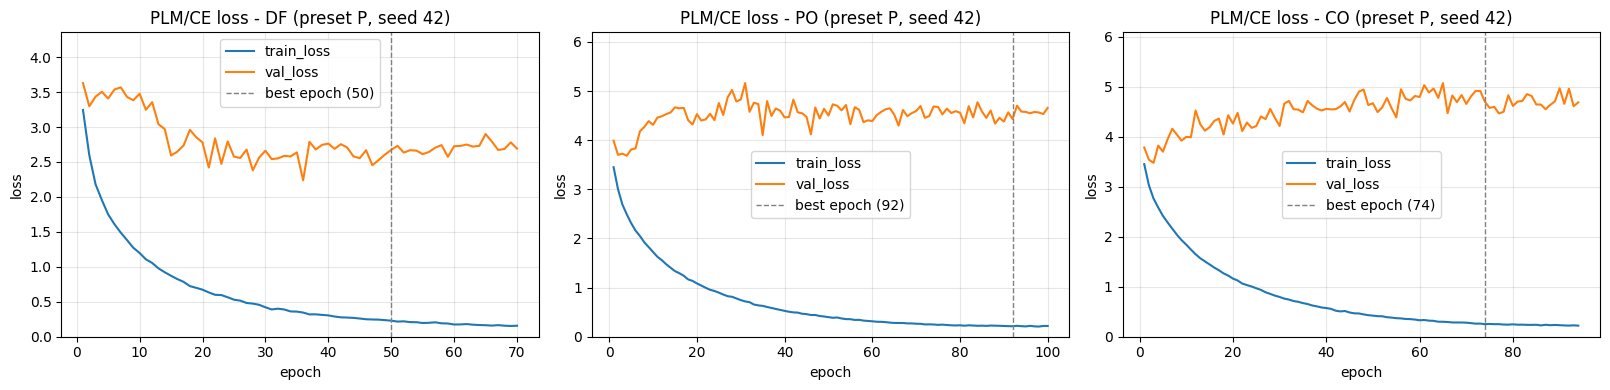

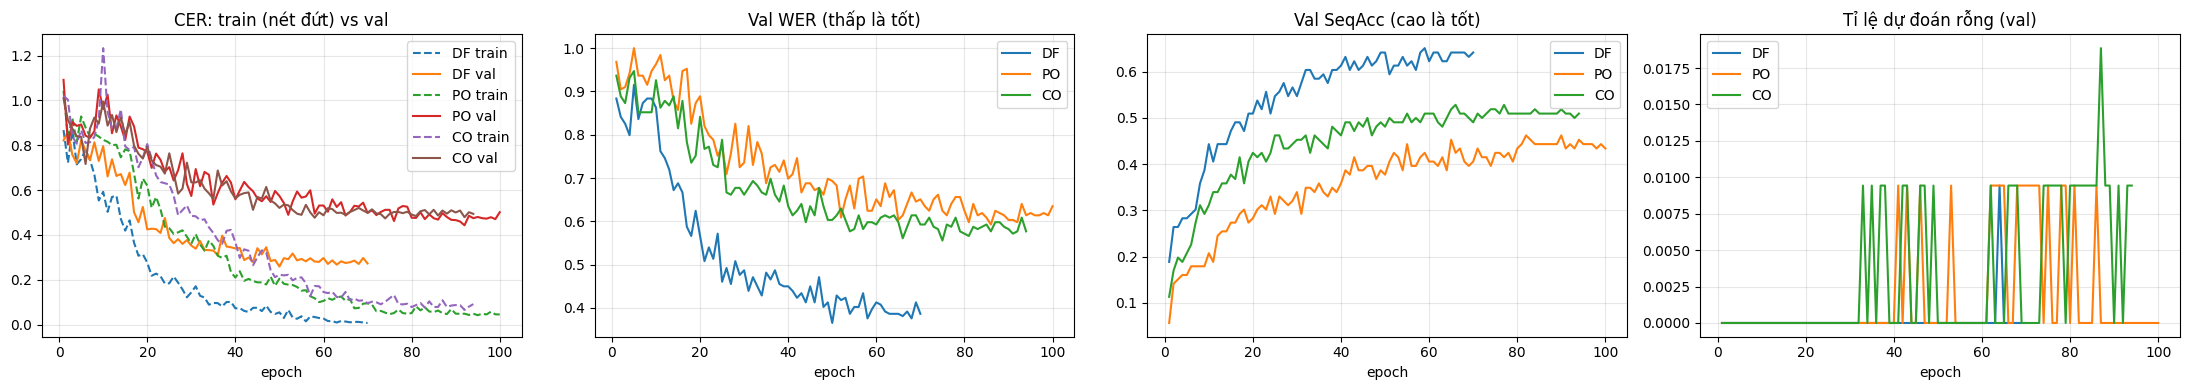

In [17]:
views = CFG.train_views
n = len(views)
fig, axes = plt.subplots(1, n, figsize=(5.4 * n, 4)); axes = np.atleast_1d(axes)
for ax, v in zip(axes, views):
    h, b = histories[v], bests[v]
    ep = np.arange(1, len(h["train_loss"]) + 1)
    ax.plot(ep, h["train_loss"], label="train_loss")
    ax.plot(ep, h["val_loss"],   label="val_loss")
    ax.axvline(b["epoch"], ls="--", c="gray", lw=1, label=f"best epoch ({b['epoch']})")
    ax.set_ylim(0, min(max(h["val_loss"]) * 1.2, 10))
    ax.set_title(f"PLM/CE loss - {VIEW_NAME[v]} (preset {CFG.preset}, seed {main_seed})"); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(CFG.out_dir / "loss_curves.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
for v in views:
    h = histories[v]; ep = np.arange(1, len(h["val_cer"]) + 1)
    axes[0].plot(ep, h["train_cer"], ls="--", label=f"{VIEW_NAME[v]} train")
    axes[0].plot(ep, h["val_cer"],   label=f"{VIEW_NAME[v]} val")
    axes[1].plot(ep, h["val_wer"],    label=VIEW_NAME[v])
    axes[2].plot(ep, h["val_seqacc"], label=VIEW_NAME[v])
    axes[3].plot(ep, h["val_empty"],  label=VIEW_NAME[v])
axes[0].set_title("CER: train (nét đứt) vs val");  axes[1].set_title("Val WER (thấp là tốt)"); axes[2].set_title("Val SeqAcc (cao là tốt)"); axes[3].set_title("Tỉ lệ dự đoán rỗng (val)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(CFG.out_dir / "metric_curves.png", dpi=150); plt.show()

## 10. Đánh giá trên tập test

**Chỉ chạy sau khi đã khóa phương pháp** (preset, preprocessing, hyperparameter, epoch) trên val. Khi đó mới đặt `CFG.final_test = True`. Mỗi (view, seed) dùng checkpoint tốt nhất của chính nó. Test giữ nguyên **toàn bộ 455 mẫu**, không lọc.

Báo cáo: CER (corpus-level, chính), WER, SeqAcc, NED, cùng số tham số, FPS và peak VRAM suy luận.

In [18]:
test_gts = test_df[CFG.label_col].tolist()
rows, test_preds, results_df = [], {}, None

CFG.final_test = True

if not CFG.final_test:
    print("CFG.final_test = False -> BỎ QUA test. Khóa phương pháp trên val trước, rồi đặt CFG.final_test = True.")
else:
    for (v, seed), r in runs.items():
        model = r["model"].to(device)
        loader = make_loader(test_df, v, train=False)
        t_loss, preds = evaluate(model, loader)
        eff = measure_efficiency(model, loader)
        test_preds[(v, seed)] = preds
        mets = {mode: compute_metrics(test_gts, preds, mode) for mode in ("strict", "no_ws")}
        for mode, m in mets.items():
            rows.append({"view": VIEW_NAME[v], "seed": seed, "mode": mode, "test_loss": t_loss, **m, **eff})
        pd.DataFrame({"row_id": test_df.row_id, "gt": test_gts, "pred": preds,
                      "edit_dist": [edit_ops(g, p)[0] for g, p in zip(test_gts, preds)]}).to_csv(r["run_dir"] / "test_predictions.csv", index=False)
        (r["run_dir"] / "test_metrics.json").write_text(json.dumps({"test_loss": t_loss, **mets, **eff}, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
        r["model"] = model.cpu()
        if device.type == "cuda": torch.cuda.empty_cache()

    results_df = pd.DataFrame(rows)
    pd.set_option("display.float_format", lambda x: f"{x:.4f}")
    pd.set_option("display.width", 220)
    show_cols = ["view", "seed", "CER", "WER", "SeqAcc", "NED", "LineAcc", "EmptyPred_rate", "params_M", "FPS", "peak_VRAM_infer_MB", "test_loss"]
    for mode in ("strict", "no_ws"):
        print(f"\n===== Kết quả test | mode = {mode} =====")
        display(results_df[results_df["mode"] == mode][show_cols].set_index(["view", "seed"]))
    if len(CFG.seeds) > 1:
        print("\n===== Trung bình ± độ lệch chuẩn theo seed (strict) =====")
        display(results_df[results_df["mode"] == "strict"].groupby("view")[["CER", "WER", "SeqAcc", "NED"]].agg(["mean", "std"]))

    results_df.to_csv(CFG.out_dir / "test_results.csv", index=False)
    pred_df = test_df[["row_id", CFG.label_col] + CFG.all_views].copy()
    for (v, seed), p in test_preds.items():
        pred_df[f"pred_{VIEW_NAME[v]}_s{seed}"] = p
    pred_df.to_csv(CFG.out_dir / "test_predictions.csv", index=False)


===== Kết quả test | mode = strict =====


,,CER,WER,SeqAcc,NED,LineAcc,EmptyPred_rate,params_M,FPS,peak_VRAM_infer_MB,test_loss
view,seed,,,,,,,,,,
DF,42,0.2437,0.3768,0.5934,0.1666,0.6612,0.0044,23.8760,263.8122,445.1035,2.2263
PO,42,0.4196,0.5664,0.4484,0.3441,0.4898,0.0132,23.8760,265.5027,446.2285,3.8923
CO,42,0.4996,0.5845,0.5011,0.3238,0.5051,0.0088,23.8760,262.3941,446.2285,4.3206



===== Kết quả test | mode = no_ws =====


,,CER,WER,SeqAcc,NED,LineAcc,EmptyPred_rate,params_M,FPS,peak_VRAM_infer_MB,test_loss
view,seed,,,,,,,,,,
DF,42,0.2433,NaN,0.6022,0.1661,NaN,0.0044,23.8760,263.8122,445.1035,2.2263
PO,42,0.4207,NaN,0.4505,0.3488,NaN,0.0132,23.8760,265.5027,446.2285,3.8923
CO,42,0.5000,NaN,0.5033,0.3268,NaN,0.0088,23.8760,262.3941,446.2285,4.3206


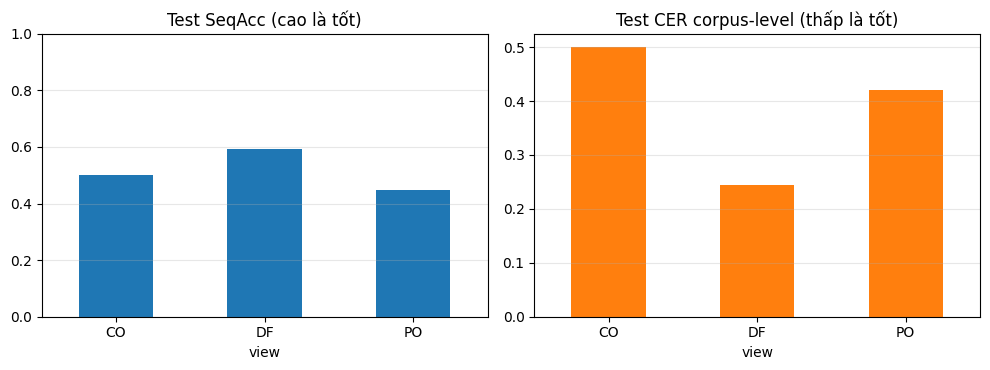

In [19]:
# So sánh nhanh giữa các view (strict, trung bình theo seed)
if results_df is None:
    print("Chưa có kết quả test (CFG.final_test = False).")
else:
    s = results_df[results_df["mode"] == "strict"].groupby("view")[["SeqAcc", "CER"]].mean()
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    s["SeqAcc"].plot.bar(ax=axes[0], color="tab:blue", rot=0);  axes[0].set_title("Test SeqAcc (cao là tốt)"); axes[0].set_ylim(0, 1)
    s["CER"].plot.bar(ax=axes[1], color="tab:orange", rot=0);   axes[1].set_title("Test CER corpus-level (thấp là tốt)")
    for ax in axes: ax.grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.show()

## 11. Phân tích lỗi và gợi ý cho bước fusion

- **Ký tự hay bị nhầm**: giúp quyết định cần augmentation hay xử lý gì.
- **Oracle** (khi train ≥ 2 view): tỉ lệ mẫu mà **ít nhất một** view đọc đúng, là trần tham khảo cho fusion.
- **Majority vote** (khi train đủ 3 view): ≥ 2 view cùng cho một chuỗi thì chọn chuỗi đó, nếu không dùng view có val CER tốt nhất.

In [20]:
if not test_preds:
    print("Bỏ qua phân tích lỗi trên test (CFG.final_test = False).")
else:
    tp = {v: test_preds[(v, main_seed)] for v in CFG.train_views}          # dự đoán của seed đầu tiên
    for v in CFG.train_views:
        cnt = Counter()
        for g, p in zip(test_gts, tp[v]):
            cnt.update(edit_ops("".join(g.split()), "".join(p.split()))[4])
        top = ", ".join(f"{a}→{b} ×{c}" for (a, b), c in cnt.most_common(10)) or "(không có lỗi thay thế)"
        print(f"[{VIEW_NAME[v]}] top nhầm lẫn: {top}")

    if len(CFG.train_views) >= 2:
        correct = np.array([[p == g for p, g in zip(tp[v], test_gts)] for v in CFG.train_views])
        print("\nSeqAcc từng view :", {VIEW_NAME[v]: round(float(correct[i].mean()), 4) for i, v in enumerate(CFG.train_views)})
        print("Oracle (>=1 view đúng):", round(float(correct.any(0).mean()), 4))
    if len(CFG.train_views) == 3:
        best_view = min(CFG.train_views, key=lambda v: bests[v]["cer"])     # chọn view dự phòng theo VAL CER
        voted = []
        for k in range(len(test_gts)):
            c = Counter(tp[v][k] for v in CFG.train_views).most_common(1)[0]
            voted.append(c[0] if c[1] >= 2 else tp[best_view][k])
        print("Majority vote         :", compute_metrics(test_gts, voted, "strict"))
    else:
        print("\n(Oracle/vote cần train đủ view; hiện chỉ train:", [VIEW_NAME[v] for v in CFG.train_views], ")")

[DF] top nhầm lẫn: 2→0 ×10, 2→1 ×7, 1→0 ×6, I→1 ×6, 3→0 ×6, A→1 ×6, 5→S ×6, 8→6 ×5, T→1 ×5, 2→8 ×4
[PO] top nhầm lẫn: 2→0 ×8, 3→1 ×8, 8→0 ×7, 3→0 ×7, 7→6 ×7, 1→2 ×6, 6→0 ×6, 2→1 ×6, 1→0 ×6, O→0 ×5
[CO] top nhầm lẫn: 3→0 ×11, 1→0 ×10, 1→2 ×9, 1→3 ×8, 2→0 ×8, 1→4 ×7, 0→6 ×7, 6→5 ×7, 0→7 ×7, C→0 ×7

SeqAcc từng view : {'DF': 0.5934, 'PO': 0.4484, 'CO': 0.5011}
Oracle (>=1 view đúng): 0.7011
Majority vote         : {'CER': 0.24121604784450537, 'WER': 0.36231884057971014, 'SeqAcc': 0.6175824175824176, 'NED': 0.15962183932415283, '1-NED': 0.8403781606758471, 'CharAcc': 0.7587839521554947, 'Acc<=1edit': 0.7384615384615385, 'Sub_rate': 0.12060802392225269, 'Del_rate': 0.06005482182905557, 'Ins_rate': 0.06055320209319711, 'EmptyPred_rate': 0.006593406593406593, 'LineAcc': 0.6738578680203046, 'n_samples': 455, 'n_chars': 4013}


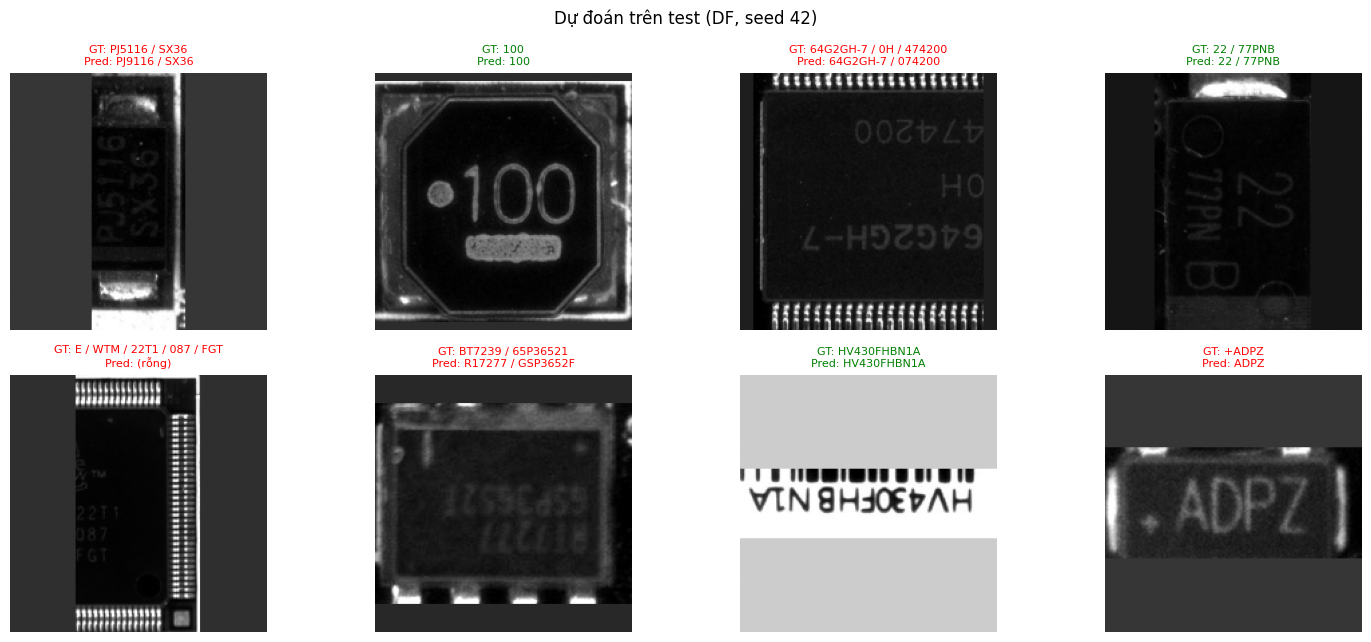

In [21]:
# --- ví dụ dự đoán trên test (đỏ = sai, xanh = đúng) ---
if not test_preds:
    print("Bỏ qua (CFG.final_test = False).")
else:
    def show(s): return s.replace("\n", " / ") if s else "(rỗng)"
    v0 = CFG.train_views[0]; pv = test_preds[(v0, main_seed)]
    idx = np.random.RandomState(1).choice(len(test_df), min(8, len(test_df)), replace=False)
    fig, axes = plt.subplots(2, 4, figsize=(15, 6.5)); axes = axes.ravel()
    for a, i in zip(axes, idx):
        a.imshow(load_image(test_df[v0 + "_abs"][i]), cmap="gray" if CFG.in_ch == 1 else None)
        ok = pv[i] == test_gts[i]
        a.set_title(f"GT: {show(test_gts[i])}\nPred: {show(pv[i])}", fontsize=8, color="green" if ok else "red")
        a.axis("off")
    plt.suptitle(f"Dự đoán trên test ({VIEW_NAME[v0]}, seed {main_seed})"); plt.tight_layout(); plt.show()

## 12. Hướng tiếp theo

1. **Chọn preset theo sanity + val CER**: so `P` (pretrained, patch 12) với `Q` (patch 8) và với `A/B` (từ đầu). Nếu `P` tốt hơn rõ rệt thì dữ liệu quá ít để train ViT từ đầu.
2. **Fine-tune từng phần**: nếu overfit nhanh (train CER thấp, val CER cao), thử `lr` nhỏ hơn cho encoder (ví dụ `1e-4`) hoặc đóng băng vài block đầu.
3. **Crop vùng chữ trước** khi đưa vào mô hình, và **chuẩn hoá hướng chữ** (xoay 0/90/180/270° rồi chọn kết quả tự tin nhất). Cả hai đều quan trọng hơn việc đổi kiến trúc nếu chữ chỉ chiếm một phần nhỏ của ảnh.
4. **Mở rộng sang PO/CO** rồi dùng majority vote như ở mục 11.
5. **Pretrain thêm trên chữ synthetic** (font in laser/dot-matrix, nền PCB) trước khi fine-tune trên dữ liệu thật.